# Trying Clairic and Luna on product analytics

Each English walkthrough example has editable `STATE`, `FIELDS` and image paths. The saved suite at the end keeps the language/detail variants.

Prediction tables start with the **expected** row. Clairic's native scalar confidence is shown as a separate row; regular Luna Responses have no equivalent per-field confidence. Predictive uncertainty uses p10/p90. Timings are measured seconds, with no expected latency target.

The expected values match the supplied examples; update them if you change the underlying facts. Calls are left for you to execute. API keys come from `../../config.json`; generation scripts are not needed.

In [90]:
# !pip install requests pandas plotly

In [136]:
import json
import base64
import time
import math
import hashlib
import unicodedata
from pathlib import Path

import requests
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Image

pd.set_option('display.max_colwidth', 5000)
colors = {'clairic': '#007f86', 'luna': '#b66a1a'}

In [137]:
with open('../../config.json') as f:
    config = json.load(f)

cloudflare_account_id = config['CLOUDFLARE_ACCOUNT_ID']
cloudflare_token = config['CLOUDFLARE_API_TOKEN']
openai_token = config['OPENAI_API_KEY']

## Calling the APIs

Two functions, one for each provider. They receive only the inputs shown in the example cells. The scalar confidence metadata is preserved in the Clairic response.

In [138]:
def call_clairic(state, fields, images=None):
    payload = {
        'model': 'clairic',
        'state': state,
        'fields': fields,
    }
    if images:
        payload['images'] = [
            {'content_type': 'image/png', 'base64': base64.b64encode(Path(path).read_bytes()).decode()}
            for path in images
        ]

    started = time.perf_counter()
    response = requests.post(
        f'https://api.cloudflare.com/client/v4/accounts/{cloudflare_account_id}/ai/run/@cf/cloudflare/clairic',
        headers={'Authorization': f'Bearer {cloudflare_token}'},
        json=payload,
        timeout=120,
    )
    response.raise_for_status()
    result = response.json()
    if result.get('success') is False:
        raise ValueError(result.get('errors'))
    result = result.get('result', result)
    if result.get('truncated'):
        raise ValueError('Clairic truncated the result')
    result['latency_seconds'] = time.perf_counter() - started
    return result

In [139]:
def call_openai(state, fields, images=None):
    content = []
    for path in images or []:
        image = base64.b64encode(Path(path).read_bytes()).decode()
        content.append({'type': 'input_image', 'image_url': f'data:image/png;base64,{image}', 'detail': 'high'})
    if state:
        content.append({'type': 'input_text', 'text': state})
    content.append({'type': 'input_text', 'text': 'Return the answers as JSON.'})

    instructions = """
Use only the supplied text and images to answer these typed fields.
Return a JSON object with an "answers" object, keyed by field name.
For text/date/number fields use {"value": ...}. Infer or calculate parameters when the evidence supports it.
Text values must be exact source spans, not summaries. Dates must be ISO dates.
For estimates use {"median": ..., "p10": ..., "p90": ...}.
For forecasts use {"steps": [{"median": ..., "p10": ..., "p90": ...}, ...]}.
Forecast steps must be chronological and match the requested horizon.
Use predictive quantiles, respect field bounds, and keep p10 <= median <= p90.
Do not add explanations or self-rated confidence scores.
Field definitions:
""" + json.dumps(fields)

    started = time.perf_counter()
    response = requests.post(
        'https://api.openai.com/v1/responses',
        headers={'Authorization': f'Bearer {openai_token}'},
        json={
            'model': 'gpt-6-luna',
            'store': False,
            'reasoning': {'effort': 'medium'},
            'instructions': instructions,
            'input': [{'role': 'user', 'content': content}],
            'text': {'format': {'type': 'json_object'}},
            'max_output_tokens': 16384,
        },
        timeout=120,
    )
    raw = response.json()
    if not response.ok:
        error = raw.get('error', {})
        raise ValueError(f"OpenAI HTTP {response.status_code}: {error.get('message', response.reason)}")
    if raw.get('status') != 'completed':
        raise ValueError('Luna did not complete the response')
    parts = [part for item in raw['output'] if item['type'] == 'message' for part in item['content']]
    if any(part['type'] == 'refusal' for part in parts):
        raise ValueError('Luna refused the request')
    text = ''.join(part['text'] for part in parts if part['type'] == 'output_text')
    result = json.loads(text)
    result['usage'] = raw.get('usage', {})
    result['latency_seconds'] = time.perf_counter() - started
    return result

## 1. Reading an experiment write-up

This note mixes explicit values, an inferable denominator and an unavailable revenue value. Edit the text or add fields here rather than editing a saved case file.

In [140]:
READ_STATE = """# EXP-001 · Intent-aware autocomplete

Hey team, here's how the autocomplete test went. We wanted to see whether suggestions that better matched what someone was looking for would help them find a product they actually wanted to buy. On mobile, typing and rewording a search can be a pain, so our bet was that getting people to the right results sooner would lead to more purchases.

We expected more people to use a suggestion, fewer searches to need another try, and ultimately a small lift in purchase conversion. Purchases were our main success metric; clicks on suggestions would help us understand why it worked, but wouldn't be enough on their own to call it a win.

We ran the A/B test with UK visitors on mobile from 2026-01-05 to 2026-01-25. Of the 118,223 eligible visitors, 59,117 got the new suggestions in B and the rest kept the current experience in A. We saw 1,585 purchasers in A and 1,543 in B. That puts conversion at about 2.68% for A and 2.61% for B: a drop of roughly 0.072 percentage points, or 2.67% relative.

So the headline isn't what we hoped for, but we also can't confidently say the new version hurt purchases. The 95% confidence interval for the B-minus-A conversion difference runs from -0.255 to +0.111 percentage points, covering both a decline and a small improvement. A brought in GBP 79,558.73 in merchandise revenue; we're still waiting for the reconciled B export, so we don't have a revenue comparison yet.

I'd keep the current autocomplete for now and try another iteration before rolling this out. The purchase result is inconclusive, and this readout doesn't include suggestion clicks or repeat searches, so we still don't know whether the new suggestions made finding a product easier. For the next round, I'd check those steps in the search journey and use what we learn to adjust the suggestions, then test again.
"""

READ_FIELDS = {'experiment_id': {'type': 'text', 'instructions': 'Experiment identifier.'},
 'start_date': {'type': 'date', 'instructions': 'Start date of the experiment.'},
 'end_date': {'type': 'date', 'instructions': 'End date of the experiment.'},
 'population': {'type': 'text',
                'instructions': 'Audience covered by the experiment, as described in the note.'},
 'decision_span': {'type': 'text', 'instructions': 'The recommendation sentence from the analyst.'},
 'control_visitors': {'type': 'number',
                      'instructions': 'Number of eligible visitors assigned to A.',
                      'integer': True},
 'control_orders': {'type': 'number',
                    'instructions': 'Number of purchasers assigned to A.',
                    'integer': True},
 'control_revenue_gbp': {'type': 'number',
                         'instructions': 'Merchandise revenue for A.',
                         'decimals': 2,
                         'unit': 'GBP'},
 'treatment_visitors': {'type': 'number',
                        'instructions': 'Number of eligible visitors assigned to B.',
                        'integer': True},
 'treatment_orders': {'type': 'number',
                      'instructions': 'Number of purchasers assigned to B.',
                      'integer': True},
 'treatment_revenue_gbp': {'type': 'number',
                           'instructions': 'Merchandise revenue for B.',
                           'decimals': 2,
                           'unit': 'GBP'}}

print(READ_STATE)
READ_FIELDS

# EXP-001 · Intent-aware autocomplete

Hey team, here's how the autocomplete test went. We wanted to see whether suggestions that better matched what someone was looking for would help them find a product they actually wanted to buy. On mobile, typing and rewording a search can be a pain, so our bet was that getting people to the right results sooner would lead to more purchases.

We expected more people to use a suggestion, fewer searches to need another try, and ultimately a small lift in purchase conversion. Purchases were our main success metric; clicks on suggestions would help us understand why it worked, but wouldn't be enough on their own to call it a win.

We ran the A/B test with UK visitors on mobile from 2026-01-05 to 2026-01-25. Of the 118,223 eligible visitors, 59,117 got the new suggestions in B and the rest kept the current experience in A. We saw 1,585 purchasers in A and 1,543 in B. That puts conversion at about 2.68% for A and 2.61% for B: a drop of roughly 0.072 per

{'experiment_id': {'type': 'text', 'instructions': 'Experiment identifier.'},
 'start_date': {'type': 'date',
  'instructions': 'Start date of the experiment.'},
 'end_date': {'type': 'date', 'instructions': 'End date of the experiment.'},
 'population': {'type': 'text',
  'instructions': 'Audience covered by the experiment, as described in the note.'},
 'decision_span': {'type': 'text',
  'instructions': 'The recommendation sentence from the analyst.'},
 'control_visitors': {'type': 'number',
  'instructions': 'Number of eligible visitors assigned to A.',
  'integer': True},
 'control_orders': {'type': 'number',
  'instructions': 'Number of purchasers assigned to A.',
  'integer': True},
 'control_revenue_gbp': {'type': 'number',
  'instructions': 'Merchandise revenue for A.',
  'decimals': 2,
  'unit': 'GBP'},
 'treatment_visitors': {'type': 'number',
  'instructions': 'Number of eligible visitors assigned to B.',
  'integer': True},
 'treatment_orders': {'type': 'number',
  'instruc

In [141]:
clairic_read = call_clairic(READ_STATE, READ_FIELDS)

In [145]:
clairic_read

{'model': 'clairic',
 'answers': {'experiment_id': {'type': 'text',
   'p_null': 0.02583533339202404,
   'span': [2, 9],
   'guess': 'EXP-001',
   'confidence': 0.9945796728134155,
   'value': 'EXP-001'},
  'start_date': {'type': 'date',
   'p_null': 2.317601229151478e-06,
   'guess': '2026-01-05',
   'confidence': 0.9999988079082982,
   'value': '2026-01-05'},
  'end_date': {'type': 'date',
   'p_null': 9.105489152716473e-05,
   'guess': '2026-01-25',
   'confidence': 0.9999990463265931,
   'value': '2026-01-25'},
  'population': {'type': 'text',
   'p_null': 0.0032840254716575146,
   'span': [699, 720],
   'guess': 'UK visitors on mobile',
   'confidence': 0.5085711479187012,
   'value': 'UK visitors on mobile'},
  'decision_span': {'type': 'text',
   'p_null': 0.0037551531568169594,
   'span': [1450, 1517],
   'guess': "I'd keep the current autocomplete for now and try another iteration",
   'confidence': 0.204769104719162,
   'value': "I'd keep the current autocomplete for now and 

In [142]:
luna_read = call_openai(READ_STATE, READ_FIELDS)

In [172]:
READING_EXPECTED = {'experiment_id': 'EXP-001',
 'start_date': '2026-01-05',
 'end_date': '2026-01-25',
 'control_visitors': 59106,
 'control_orders': 1585,
 'treatment_visitors': 59117,
 'treatment_orders': 1543,
 'control_revenue_gbp': 79558.73,
 'treatment_revenue_gbp': None,
 'population': 'UK visitors on mobile',
 'decision_span': "I'd keep the current autocomplete for now and try another iteration before rolling this out."}

reading = pd.DataFrame({
    'expected': READING_EXPECTED,
    'clairic': {k:v.get('value') for k,v in clairic_read['answers'].items()},
    'luna': {k:v.get('value') for k,v in luna_read['answers'].items()},
    'clairic_confidence': {k:v.get('confidence') for k,v in clairic_read['answers'].items()},
}).T
reading.loc['clairic','elapsed_seconds'] = clairic_read['latency_seconds']
reading.loc['luna','elapsed_seconds'] = luna_read['latency_seconds']
comparison = reading.T.drop('elapsed_seconds', axis=0)[['expected', 'luna', 'clairic', 'clairic_confidence']]
count_fields = [field for field, spec in READ_FIELDS.items() if spec.get('integer')]
revenue_fields = [field for field in comparison.index if field.endswith('_revenue_gbp')]
comparison.style.format(precision=4, thousands=',', na_rep='—').format(
    '{:,.0f}', na_rep='—', subset=pd.IndexSlice[count_fields, ['expected', 'luna', 'clairic']]
).format('{:,.2f}', na_rep='—', subset=pd.IndexSlice[revenue_fields, ['expected', 'luna', 'clairic']])


,expected,luna,clairic,clairic_confidence
experiment_id,EXP-001,EXP-001,EXP-001,0.9946
start_date,2026-01-05,2026-01-05,2026-01-05,1.0000
end_date,2026-01-25,2026-01-25,2026-01-25,1.0000
control_visitors,"59,106","59,106","59,106",0.9990
control_orders,"1,585","1,585","1,585",0.9947
treatment_visitors,"59,117","59,117","59,106",0.9209
treatment_orders,"1,543","1,543","1,543",0.9998
control_revenue_gbp,"79,558.73","79,558.73","79,558.73",1.0000
treatment_revenue_gbp,—,—,—,0.0330
population,UK visitors on mobile,UK visitors on mobile,UK visitors on mobile,0.5086


In [162]:
reading[['elapsed_seconds']].dropna()

,elapsed_seconds
clairic,0.376320
luna,3.877831


## 2. Can they calculate uplift?

Compare three routes: ask for conversion/uplift directly; ask for counts, conversions and uplift **together in one call**; or explicitly extract counts and then make a second conversion call.

The comparison uses the same four conversion/uplift fields in all three routes. Extra count outputs are checked separately. The one-shot version does not impose a processing order. Cloudflare documents non-text fields as sharing a pass when they fit. [Model reference](https://developers.cloudflare.com/workers-ai/models/clairic/).

In [165]:
MATH_STATE = """# EXP-001 · Intent-aware autocomplete

Hey team, here's the data from the autocomplete test. We wanted to see whether suggestions that better matched what someone was looking for would help them find a product they actually wanted to buy. On mobile, typing and rewording a search can be a pain, so our bet was that getting people to the right results sooner would lead to more purchases.

We expected more people to use a suggestion, fewer searches to need another try, and ultimately more people to buy something. Purchases were our main success metric; clicks on suggestions would help us understand what happened along the way.

We ran the A/B test with UK visitors on mobile from 2026-01-05 to 2026-01-25. Of the 118,223 eligible visitors, 59,117 got the new suggestions in B and the rest kept the current experience in A. We saw 1,585 purchasers in A and 1,543 in B.

A brought in GBP 79,558.73 in merchandise revenue. We're still waiting for the reconciled B export, so the revenue comparison will have to wait.
"""

MATH_FIELDS = {'control_orders': {'type': 'number',
                    'integer': True,
                    'instructions': 'Number of purchasers in control group A.'},
 'control_visitors': {'type': 'number',
                      'integer': True,
                      'instructions': 'Number of eligible visitors in control group A.'},
 'treatment_orders': {'type': 'number',
                      'integer': True,
                      'instructions': 'Number of purchasers in experiment group B.'},
 'treatment_visitors': {'type': 'number',
                        'integer': True,
                        'instructions': 'Number of eligible visitors in experiment group B.'},
 'control_cvr_pct': {'type': 'number',
                     'instructions': 'Purchase conversion rate for A, expressed as a percentage.',
                     'decimals': 3,
                     'unit': 'percent'},
 'treatment_cvr_pct': {'type': 'number',
                       'instructions': 'Purchase conversion rate for B, expressed as a percentage.',
                       'decimals': 3,
                       'unit': 'percent'},
 'absolute_uplift_pp': {'type': 'number',
                        'instructions': 'How many percentage points higher or lower is purchase '
                                        'conversion in B than in A?',
                        'decimals': 3,
                        'unit': 'percentage points'},
 'relative_uplift_pct': {'type': 'number',
                         'instructions': 'Percentage change in purchase conversion for B relative to A.',
                         'decimals': 3,
                         'unit': 'percent'}}

print(MATH_STATE)
MATH_FIELDS

# EXP-001 · Intent-aware autocomplete

Hey team, here's the data from the autocomplete test. We wanted to see whether suggestions that better matched what someone was looking for would help them find a product they actually wanted to buy. On mobile, typing and rewording a search can be a pain, so our bet was that getting people to the right results sooner would lead to more purchases.

We expected more people to use a suggestion, fewer searches to need another try, and ultimately more people to buy something. Purchases were our main success metric; clicks on suggestions would help us understand what happened along the way.

We ran the A/B test with UK visitors on mobile from 2026-01-05 to 2026-01-25. Of the 118,223 eligible visitors, 59,117 got the new suggestions in B and the rest kept the current experience in A. We saw 1,585 purchasers in A and 1,543 in B.

A brought in GBP 79,558.73 in merchandise revenue. We're still waiting for the reconciled B export, so the revenue comparison w

{'control_orders': {'type': 'number',
  'integer': True,
  'instructions': 'Number of purchasers in control group A.'},
 'control_visitors': {'type': 'number',
  'integer': True,
  'instructions': 'Number of eligible visitors in control group A.'},
 'treatment_orders': {'type': 'number',
  'integer': True,
  'instructions': 'Number of purchasers in experiment group B.'},
 'treatment_visitors': {'type': 'number',
  'integer': True,
  'instructions': 'Number of eligible visitors in experiment group B.'},
 'control_cvr_pct': {'type': 'number',
  'instructions': 'Purchase conversion rate for A, expressed as a percentage.',
  'decimals': 3,
  'unit': 'percent'},
 'treatment_cvr_pct': {'type': 'number',
  'instructions': 'Purchase conversion rate for B, expressed as a percentage.',
  'decimals': 3,
  'unit': 'percent'},
 'absolute_uplift_pp': {'type': 'number',
  'instructions': 'How many percentage points higher or lower is purchase conversion in B than in A?',
  'decimals': 3,
  'unit': 'p

In [168]:
clairic_direct = call_clairic(MATH_STATE, MATH_FIELDS)
luna_direct = call_openai(MATH_STATE, MATH_FIELDS)

In [ ]:
MATH_EXPECTED = {'control_orders': 1585,
 'control_visitors': 59106,
 'treatment_orders': 1543,
 'treatment_visitors': 59117,
 'control_cvr_pct': 2.681622847088282,
 'treatment_cvr_pct': 2.610078319265186,
 'absolute_uplift_pp': -0.07154452782309612,
 'relative_uplift_pct': -2.6679563795027894}

direct = pd.DataFrame({
    'expected': MATH_EXPECTED,
    'clairic': {k:v.get('value') for k,v in clairic_direct['answers'].items()},
    'luna': {k:v.get('value') for k,v in luna_direct['answers'].items()},
    'clairic_confidence': {k:v.get('confidence') for k,v in clairic_direct['answers'].items()},
}).T
direct.loc['clairic','elapsed_seconds'] = clairic_direct['latency_seconds']
direct.loc['luna','elapsed_seconds'] = luna_direct['latency_seconds']
comparison = direct.T.drop('elapsed_seconds', axis=0)[['expected', 'luna', 'clairic', 'clairic_confidence']]
count_fields = [field for field, spec in MATH_FIELDS.items() if spec.get('integer')]
revenue_fields = [field for field in comparison.index if field.endswith('_revenue_gbp')]
comparison.style.format(precision=4, thousands=',', na_rep='—').format(
    '{:,.0f}', na_rep='—', subset=pd.IndexSlice[count_fields, ['expected', 'luna', 'clairic']]
).format('{:,.2f}', na_rep='—', subset=pd.IndexSlice[revenue_fields, ['expected', 'luna', 'clairic']])


## 3. Reading a busier A/B chart

These are the **exact PNG files** passed to the models, not re-rendered Plotly JSON. We ask about counts, rates, confidence intervals, dates, experiment type and the better option for purchase conversion.

`equal` means the 95% interval for B-minus-A includes zero; it is not proof of equivalence or a commercial rollout decision.

EXP-003: Verified reviews above the fold. We tested showing verified reviews higher up on the product page from 2026-01-29 to 2026-02-11. Experiment type: Product detail. Here’s the results dashboard.


{'experiment_id': {'type': 'text', 'instructions': 'Experiment identifier.'},
 'experiment_type': {'type': 'text',
  'instructions': 'Experiment family/type stated in the note.'},
 'start_date': {'type': 'date', 'instructions': 'First assignment date.'},
 'end_date': {'type': 'date', 'instructions': 'Last assignment date.'},
 'better_option': {'type': 'text',
  'instructions': 'Select A, B or equal from the decision vocabulary in the note. Judge purchase conversion only: choose B if the 95% interval for B-minus-A is entirely positive, A if entirely negative, otherwise equal. Here equal means insufficient evidence of a difference.'},
 'control_visitors': {'type': 'number',
  'instructions': 'Eligible visitors assigned to A; the CVR denominator.',
  'integer': True},
 'control_orders': {'type': 'number',
  'instructions': 'Purchasers in A; the CVR numerator.',
  'integer': True},
 'control_cvr_pct': {'type': 'number',
  'instructions': 'Purchase conversion rate in A.',
  'decimals': 2,
 

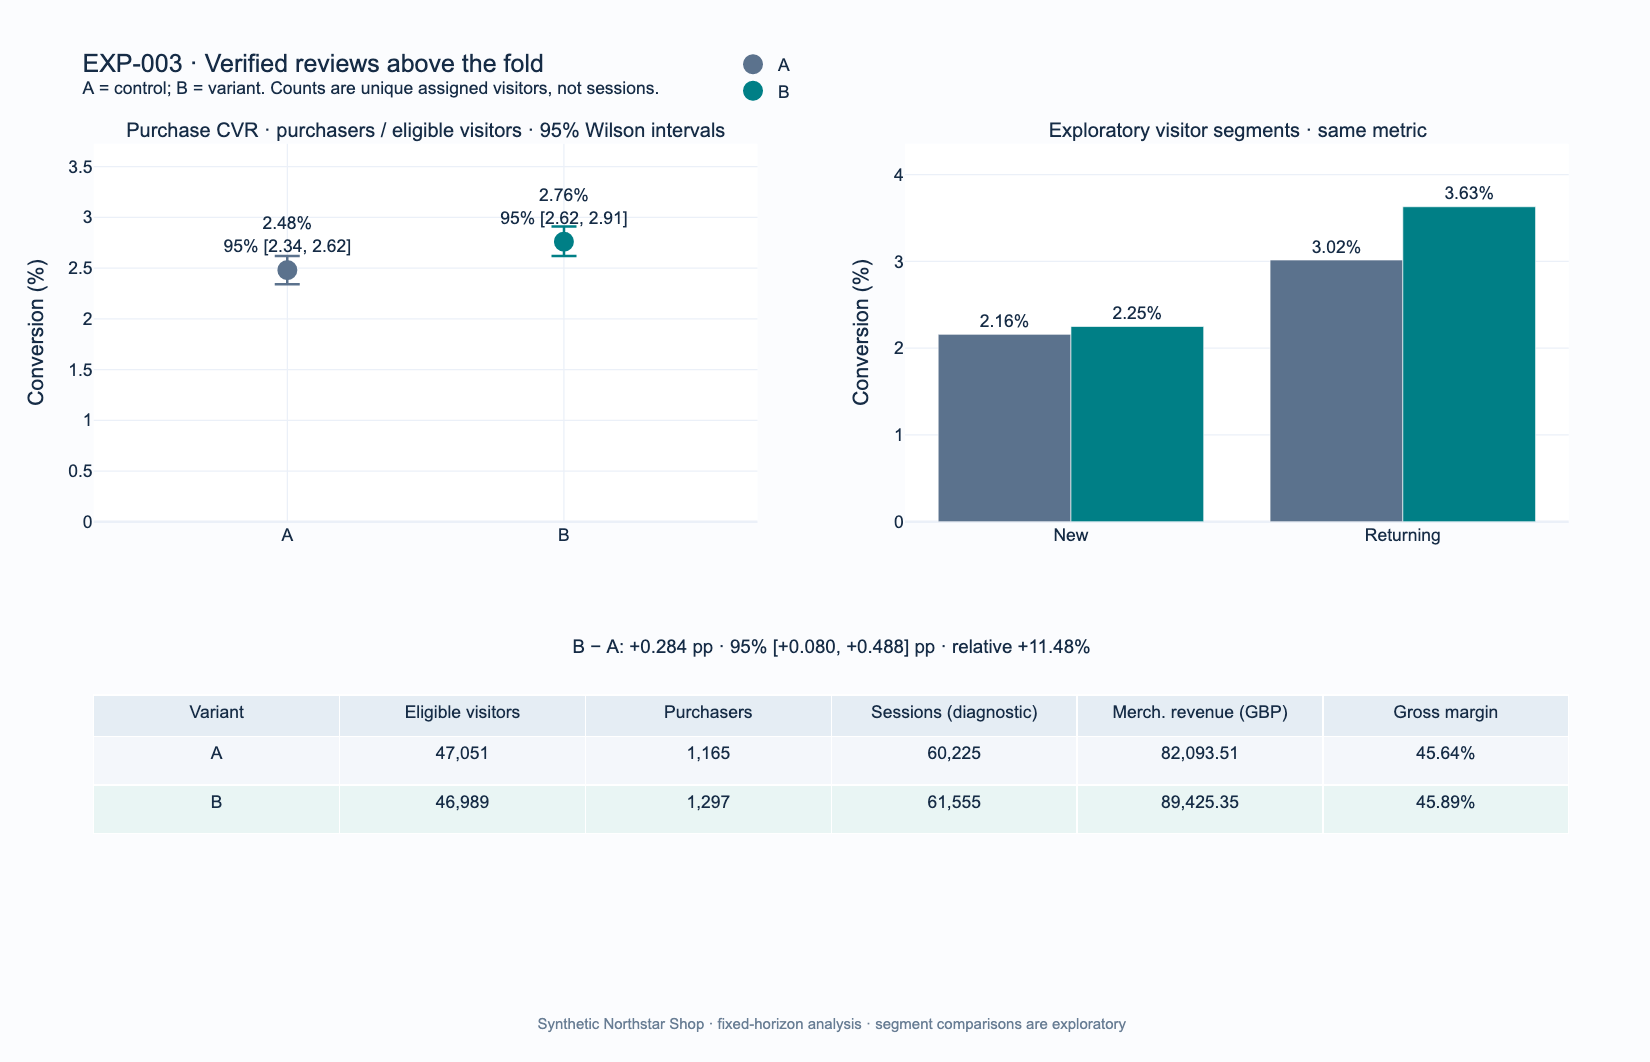

In [174]:
CHART_STATE = """EXP-003: Verified reviews above the fold. We tested showing verified reviews higher up on the product page from 2026-01-29 to 2026-02-11. Experiment type: Product detail. Here’s the results dashboard."""

CHART_FIELDS = {'experiment_id': {'type': 'text', 'instructions': 'Experiment identifier.'},
 'experiment_type': {'type': 'text', 'instructions': 'Experiment family/type stated in the note.'},
 'start_date': {'type': 'date', 'instructions': 'First assignment date.'},
 'end_date': {'type': 'date', 'instructions': 'Last assignment date.'},
 'better_option': {'type': 'text',
                   'instructions': 'Select A, B or equal from the decision vocabulary in the note. '
                                   'Judge purchase conversion only: choose B if the 95% interval for '
                                   'B-minus-A is entirely positive, A if entirely negative, otherwise '
                                   'equal. Here equal means insufficient evidence of a difference.'},
 'control_visitors': {'type': 'number',
                      'instructions': 'Eligible visitors assigned to A; the CVR denominator.',
                      'integer': True},
 'control_orders': {'type': 'number',
                    'instructions': 'Purchasers in A; the CVR numerator.',
                    'integer': True},
 'control_cvr_pct': {'type': 'number',
                     'instructions': 'Purchase conversion rate in A.',
                     'decimals': 2,
                     'unit': 'percent'},
 'control_ci_low_pct': {'type': 'number',
                        'instructions': 'Lower endpoint of the 95% conversion-rate interval for A.',
                        'decimals': 2,
                        'unit': 'percent'},
 'control_ci_high_pct': {'type': 'number',
                         'instructions': 'Upper endpoint of the 95% conversion-rate interval for A.',
                         'decimals': 2,
                         'unit': 'percent'},
 'treatment_visitors': {'type': 'number',
                        'instructions': 'Eligible visitors assigned to B; the CVR denominator.',
                        'integer': True},
 'treatment_orders': {'type': 'number',
                      'instructions': 'Purchasers in B; the CVR numerator.',
                      'integer': True},
 'treatment_cvr_pct': {'type': 'number',
                       'instructions': 'Purchase conversion rate in B.',
                       'decimals': 2,
                       'unit': 'percent'},
 'treatment_ci_low_pct': {'type': 'number',
                          'instructions': 'Lower endpoint of the 95% conversion-rate interval for B.',
                          'decimals': 2,
                          'unit': 'percent'},
 'treatment_ci_high_pct': {'type': 'number',
                           'instructions': 'Upper endpoint of the 95% conversion-rate interval for B.',
                           'decimals': 2,
                           'unit': 'percent'},
 'relative_uplift_pct': {'type': 'number',
                         'instructions': 'Relative percentage difference in purchase conversion, B '
                                         'versus A.',
                         'decimals': 2,
                         'unit': 'percent'}}

CHART_IMAGES = ['data/charts/EXP-003_comparison.png']

print(CHART_STATE)
display(CHART_FIELDS)
for path in CHART_IMAGES:
    display(Image(filename=path, width=1100))

In [175]:
clairic_chart = call_clairic(CHART_STATE, CHART_FIELDS, images=CHART_IMAGES)
luna_chart = call_openai(CHART_STATE, CHART_FIELDS, images=CHART_IMAGES)

CHART_COMPARISON_EXPECTED = {'experiment_id': 'EXP-003',
 'experiment_type': 'Product detail',
 'start_date': '2026-01-29',
 'end_date': '2026-02-11',
 'better_option': 'B',
 'control_visitors': 47051,
 'control_orders': 1165,
 'control_cvr_pct': 2.48,
 'control_ci_low_pct': 2.34,
 'control_ci_high_pct': 2.62,
 'treatment_visitors': 46989,
 'treatment_orders': 1297,
 'treatment_cvr_pct': 2.76,
 'treatment_ci_low_pct': 2.62,
 'treatment_ci_high_pct': 2.91,
 'relative_uplift_pct': 11.48}

chart_comparison = pd.DataFrame({
    'expected': CHART_COMPARISON_EXPECTED,
    'clairic': {k:v.get('value') for k,v in clairic_chart['answers'].items()},
    'luna': {k:v.get('value') for k,v in luna_chart['answers'].items()},
    'clairic_confidence': {k:v.get('confidence') for k,v in clairic_chart['answers'].items()},
}).T
chart_comparison.loc['clairic','elapsed_seconds'] = clairic_chart['latency_seconds']
chart_comparison.loc['luna','elapsed_seconds'] = luna_chart['latency_seconds']
comparison = chart_comparison.T.drop('elapsed_seconds', axis=0)[['expected', 'luna', 'clairic', 'clairic_confidence']]
count_fields = [field for field, spec in CHART_FIELDS.items() if spec.get('integer')]
revenue_fields = [field for field in comparison.index if field.endswith('_revenue_gbp')]
comparison.style.format(precision=4, thousands=',', na_rep='—').format(
    '{:,.0f}', na_rep='—', subset=pd.IndexSlice[count_fields, ['expected', 'luna', 'clairic']]
).format('{:,.2f}', na_rep='—', subset=pd.IndexSlice[revenue_fields, ['expected', 'luna', 'clairic']])


,expected,luna,clairic,clairic_confidence
experiment_id,EXP-003,EXP-003,EXP-003,0.9999
experiment_type,Product detail,Product detail,Product detail,0.9890
start_date,2026-01-29,2026-01-29,2026-01-29,0.9983
end_date,2026-02-11,2026-02-11,2026-02-11,0.9992
better_option,B,B,b,0.2156
control_visitors,"47,051","47,051","47,051",0.8055
control_orders,"1,165","1,165","1,165",0.9997
control_cvr_pct,2.4800,2.4800,2.4800,0.9947
control_ci_low_pct,2.3400,2.3400,2.3400,0.9583
control_ci_high_pct,2.6200,2.6200,2.6200,0.9492


### What if the dates are only on another chart?

Same questions, three PNGs: the outcome dashboard, daily assignment **lines**, and a horizontal stacked acquisition-mix chart. There are no start/end callouts; the dates must be read from the assignment plot's x-axis.

EXP-003: Verified reviews above the fold. We tested showing verified reviews higher up on the product page. Experiment type: Product detail. Here’s the results dashboard.


{'experiment_id': {'type': 'text', 'instructions': 'Experiment identifier.'},
 'experiment_type': {'type': 'text',
  'instructions': 'Experiment family/type stated in the note.'},
 'start_date': {'type': 'date', 'instructions': 'First assignment date.'},
 'end_date': {'type': 'date', 'instructions': 'Last assignment date.'},
 'better_option': {'type': 'text',
  'instructions': 'Select A, B or equal from the decision vocabulary in the note. Judge purchase conversion only: choose B if the 95% interval for B-minus-A is entirely positive, A if entirely negative, otherwise equal. Here equal means insufficient evidence of a difference.'},
 'control_visitors': {'type': 'number',
  'instructions': 'Eligible visitors assigned to A; the CVR denominator.',
  'integer': True},
 'control_orders': {'type': 'number',
  'instructions': 'Purchasers in A; the CVR numerator.',
  'integer': True},
 'control_cvr_pct': {'type': 'number',
  'instructions': 'Purchase conversion rate in A.',
  'decimals': 2,
 

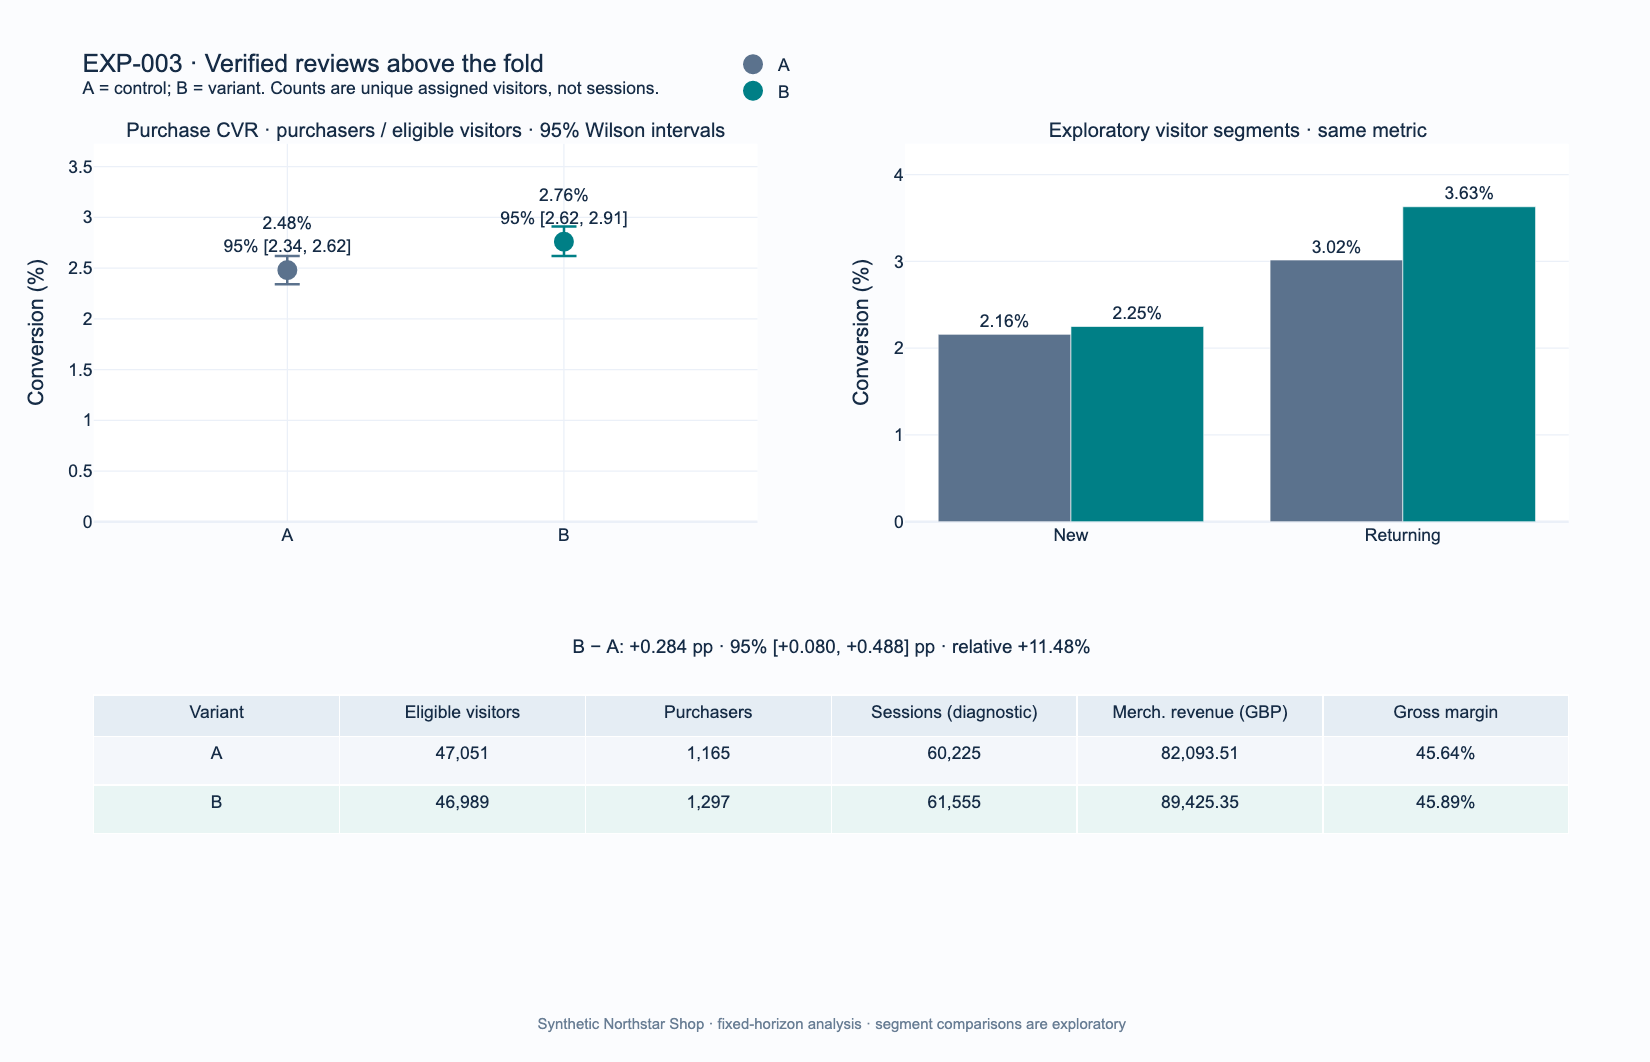

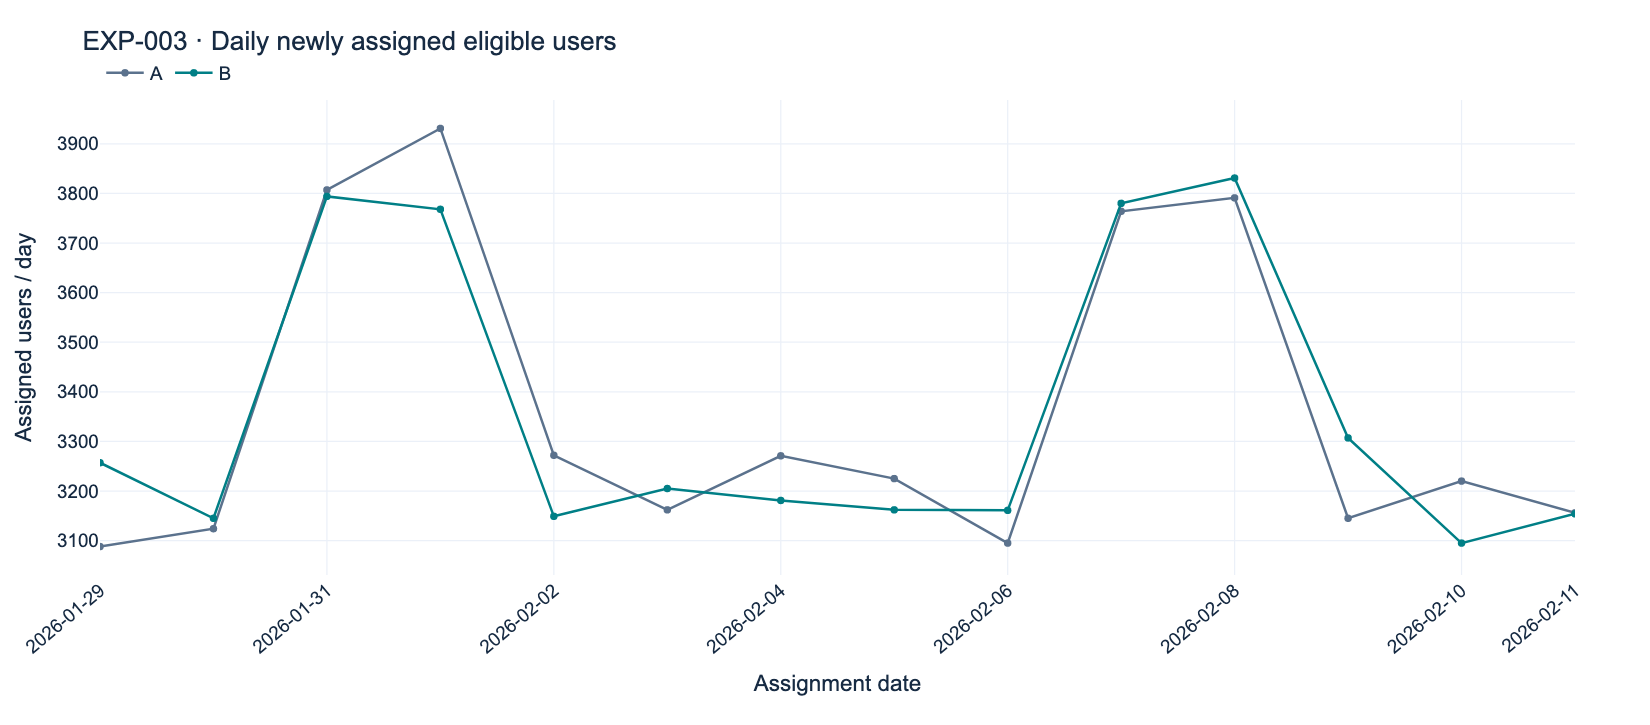

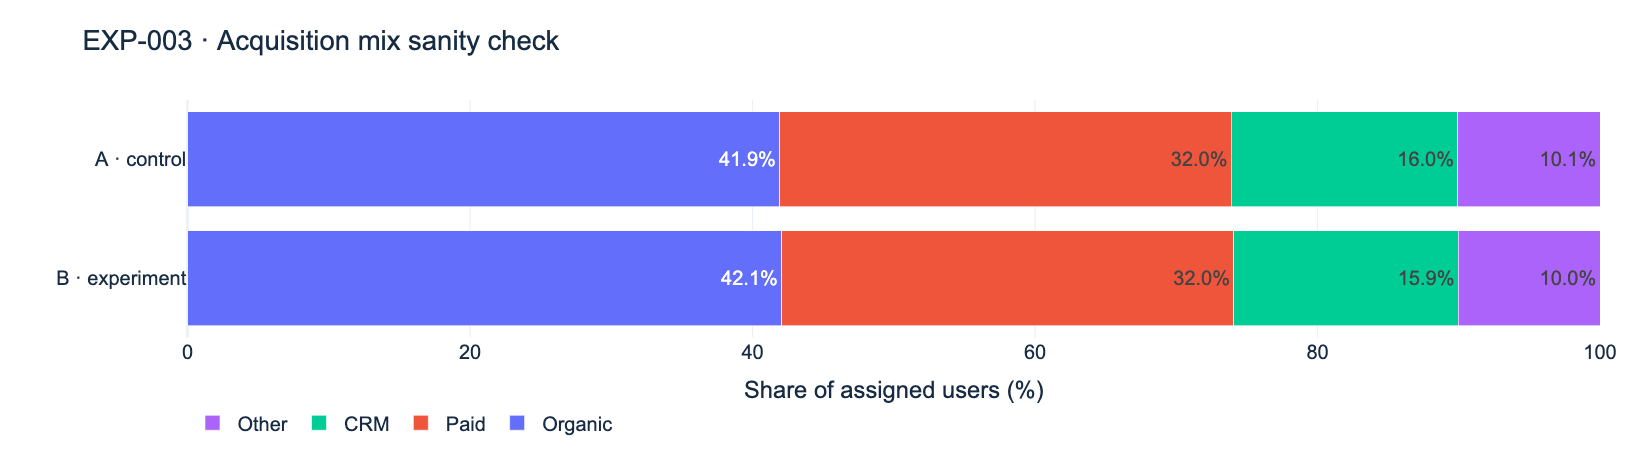

In [178]:
MULTI_CHART_STATE = """EXP-003: Verified reviews above the fold. We tested showing verified reviews higher up on the product page. Experiment type: Product detail. Here’s the results dashboard."""

MULTI_CHART_FIELDS = CHART_FIELDS

MULTI_CHART_IMAGES = ['data/charts/EXP-003_comparison.png',
 'data/charts/EXP-003_assignment_dates.png',
 'data/charts/EXP-003_mix.png']

print(MULTI_CHART_STATE)
display(MULTI_CHART_FIELDS)
for path in MULTI_CHART_IMAGES:
    display(Image(filename=path, width=1100))

In [179]:
clairic_multi_chart = call_clairic(MULTI_CHART_STATE, MULTI_CHART_FIELDS, images=MULTI_CHART_IMAGES)
luna_multi_chart = call_openai(MULTI_CHART_STATE, MULTI_CHART_FIELDS, images=MULTI_CHART_IMAGES)

MULTI_CHART_COMPARISON_EXPECTED = {'experiment_id': 'EXP-003',
 'experiment_type': 'Product detail',
 'start_date': '2026-01-29',
 'end_date': '2026-02-11',
 'better_option': 'B',
 'control_visitors': 47051,
 'control_orders': 1165,
 'control_cvr_pct': 2.48,
 'control_ci_low_pct': 2.34,
 'control_ci_high_pct': 2.62,
 'treatment_visitors': 46989,
 'treatment_orders': 1297,
 'treatment_cvr_pct': 2.76,
 'treatment_ci_low_pct': 2.62,
 'treatment_ci_high_pct': 2.91,
 'relative_uplift_pct': 11.48}

multi_chart_comparison = pd.DataFrame({
    'expected': MULTI_CHART_COMPARISON_EXPECTED,
    'clairic': {k:v.get('value') for k,v in clairic_multi_chart['answers'].items()},
    'luna': {k:v.get('value') for k,v in luna_multi_chart['answers'].items()},
    'clairic_confidence': {k:v.get('confidence') for k,v in clairic_multi_chart['answers'].items()},
}).T
multi_chart_comparison.loc['clairic','elapsed_seconds'] = clairic_multi_chart['latency_seconds']
multi_chart_comparison.loc['luna','elapsed_seconds'] = luna_multi_chart['latency_seconds']
comparison = multi_chart_comparison.T.drop('elapsed_seconds', axis=0)[['expected', 'luna', 'clairic', 'clairic_confidence']]
count_fields = [field for field, spec in MULTI_CHART_FIELDS.items() if spec.get('integer')]
revenue_fields = [field for field in comparison.index if field.endswith('_revenue_gbp')]
comparison.style.format(precision=4, thousands=',', na_rep='—').format(
    '{:,.0f}', na_rep='—', subset=pd.IndexSlice[count_fields, ['expected', 'luna', 'clairic']]
).format('{:,.2f}', na_rep='—', subset=pd.IndexSlice[revenue_fields, ['expected', 'luna', 'clairic']])


,expected,luna,clairic,clairic_confidence
experiment_id,EXP-003,EXP-003,EXP-003,1.0000
experiment_type,Product detail,Product detail,Product detail,0.9792
start_date,2026-01-29,2026-01-29,2026-01-29,0.9995
end_date,2026-02-11,2026-02-11,2026-02-11,0.9998
better_option,B,B,b,0.2604
control_visitors,"47,051","47,051","47,051",0.8141
control_orders,"1,165","1,165","1,165",0.9996
control_cvr_pct,2.4800,2.4800,2.4800,0.9939
control_ci_low_pct,2.3400,2.3400,2.3400,0.9486
control_ci_high_pct,2.6200,2.6200,2.6200,0.9441


### Just the facts: numbers and dates

No winner judgment this time. Read the experiment ID, A/B visitor and purchaser counts, conversion rates and interval endpoints from the dashboard, and the first/last assignment dates from the timeline x-axis. The text supplies none of these answers. These exact PNGs are passed to both models.


In [ ]:
CHART_FACTS_STATE = 'Here are the experiment results and daily assignment charts. Pull out the requested facts from the images.'

CHART_FACTS_FIELDS = {'experiment_id': {'type': 'text', 'instructions': 'Experiment identifier.'},
 'start_date': {'type': 'date',
                'instructions': 'First date with assigned visitors, read from the daily assignment '
                                'chart x-axis.'},
 'end_date': {'type': 'date',
              'instructions': 'Last date with assigned visitors, read from the daily assignment '
                              'chart x-axis.'},
 'control_visitors': {'type': 'number',
                      'instructions': 'Eligible visitors assigned to A; the CVR denominator.',
                      'integer': True},
 'control_orders': {'type': 'number',
                    'instructions': 'Purchasers in A; the CVR numerator.',
                    'integer': True},
 'control_cvr_pct': {'type': 'number',
                     'instructions': 'Purchase conversion rate in A.',
                     'decimals': 2,
                     'unit': 'percent'},
 'control_ci_low_pct': {'type': 'number',
                        'instructions': 'Lower endpoint of the 95% conversion-rate interval for A.',
                        'decimals': 2,
                        'unit': 'percent'},
 'control_ci_high_pct': {'type': 'number',
                         'instructions': 'Upper endpoint of the 95% conversion-rate interval for '
                                         'A.',
                         'decimals': 2,
                         'unit': 'percent'},
 'treatment_visitors': {'type': 'number',
                        'instructions': 'Eligible visitors assigned to B; the CVR denominator.',
                        'integer': True},
 'treatment_orders': {'type': 'number',
                      'instructions': 'Purchasers in B; the CVR numerator.',
                      'integer': True},
 'treatment_cvr_pct': {'type': 'number',
                       'instructions': 'Purchase conversion rate in B.',
                       'decimals': 2,
                       'unit': 'percent'},
 'treatment_ci_low_pct': {'type': 'number',
                          'instructions': 'Lower endpoint of the 95% conversion-rate interval for '
                                          'B.',
                          'decimals': 2,
                          'unit': 'percent'},
 'treatment_ci_high_pct': {'type': 'number',
                           'instructions': 'Upper endpoint of the 95% conversion-rate interval for '
                                           'B.',
                           'decimals': 2,
                           'unit': 'percent'}}

CHART_FACTS_IMAGES = ['data/charts/EXP-003_comparison.png', 'data/charts/EXP-003_assignment_dates.png']

print(CHART_FACTS_STATE)
display(CHART_FACTS_FIELDS)
for path in CHART_FACTS_IMAGES:
    display(Image(filename=path, width=1100))


In [ ]:
clairic_chart_facts = call_clairic(CHART_FACTS_STATE, CHART_FACTS_FIELDS, images=CHART_FACTS_IMAGES)
luna_chart_facts = call_openai(CHART_FACTS_STATE, CHART_FACTS_FIELDS, images=CHART_FACTS_IMAGES)

CHART_FACTS_EXPECTED = {'experiment_id': 'EXP-003',
 'start_date': '2026-01-29',
 'end_date': '2026-02-11',
 'control_visitors': 47051,
 'control_orders': 1165,
 'control_cvr_pct': 2.48,
 'control_ci_low_pct': 2.34,
 'control_ci_high_pct': 2.62,
 'treatment_visitors': 46989,
 'treatment_orders': 1297,
 'treatment_cvr_pct': 2.76,
 'treatment_ci_low_pct': 2.62,
 'treatment_ci_high_pct': 2.91}
chart_facts_comparison = pd.DataFrame({
    'expected':CHART_FACTS_EXPECTED,
    'luna':{k:v.get('value') for k,v in luna_chart_facts['answers'].items()},
    'clairic':{k:v.get('value') for k,v in clairic_chart_facts['answers'].items()},
    'clairic_confidence':{k:v.get('confidence') for k,v in clairic_chart_facts['answers'].items()},
})
count_fields = [field for field,spec in CHART_FACTS_FIELDS.items() if spec.get('integer')]
chart_facts_comparison.style.format(precision=4, thousands=',', na_rep='—').format(
    '{:,.0f}', na_rep='—', subset=pd.IndexSlice[count_fields,['expected','luna','clairic']]
)


## 4. Guessing the impact of a future experiment

Share ten completed experiments and the proposed change, with descriptions, types, markets and devices. We do **not** tell the model the expected signs, effect sizes or multiplicative structure.

For scoring, the toy dataset uses larger signed UI effects and smaller positive performance/bug-fix effects. The numerical reference rule is shown after the calls and is not part of the request. This is a designed synthetic example, not a claim that real experiment outcomes follow this rule.

In [180]:
ESTIMATION_HISTORY = [{'experiment_id': 'HIST-01',
  'experiment_type': 'UI changes',
  'device': 'mobile',
  'market': 'Germany',
  'observed_uplift_pct': 14.9,
  'description': 'Allow shoppers to check out as guests instead of creating an account before payment.'},
 {'experiment_id': 'HIST-02',
  'experiment_type': 'UI changes',
  'device': 'desktop',
  'market': 'UK',
  'observed_uplift_pct': -5.93,
  'description': 'Require shoppers to create an account and complete a profile before reaching '
                 'payment.'},
 {'experiment_id': 'HIST-03',
  'experiment_type': 'UI changes',
  'device': 'mobile',
  'market': 'UK',
  'observed_uplift_pct': 9.97,
  'description': 'Pre-fill known delivery details and remove two optional fields from the checkout '
                 'form.'},
 {'experiment_id': 'HIST-04',
  'experiment_type': 'UI changes',
  'device': 'desktop',
  'market': 'Germany',
  'observed_uplift_pct': -8.89,
  'description': 'Add a mandatory preferences screen between the basket and payment pages.'},
 {'experiment_id': 'HIST-05',
  'experiment_type': 'Performance improvements',
  'device': 'mobile',
  'market': 'Germany',
  'observed_uplift_pct': 2.02,
  'description': 'Compress product images to reduce initial page loading time without changing the page '
                 'layout.'},
 {'experiment_id': 'HIST-06',
  'experiment_type': 'Performance improvements',
  'device': 'desktop',
  'market': 'UK',
  'observed_uplift_pct': 0.8,
  'description': 'Cache category-page responses so repeat requests load faster, keeping the content '
                 'unchanged.'},
 {'experiment_id': 'HIST-07',
  'experiment_type': 'Performance improvements',
  'device': 'mobile',
  'market': 'UK',
  'observed_uplift_pct': 1.44,
  'description': 'Defer off-screen scripts to improve mobile page loading without altering the purchase '
                 'flow.'},
 {'experiment_id': 'HIST-08',
  'experiment_type': 'Bug fixes',
  'device': 'mobile',
  'market': 'Germany',
  'observed_uplift_pct': 1.21,
  'description': 'Fix an intermittent checkout issue where the first tap on the submit button is '
                 'ignored.'},
 {'experiment_id': 'HIST-09',
  'experiment_type': 'Bug fixes',
  'device': 'desktop',
  'market': 'UK',
  'observed_uplift_pct': 0.46,
  'description': 'Fix a rare postcode-validation error that rejects valid payment details.'},
 {'experiment_id': 'HIST-10',
  'experiment_type': 'UI changes',
  'device': 'desktop',
  'market': 'Germany',
  'observed_uplift_pct': 8.95,
  'description': 'Preserve basket contents when shoppers return from a product page instead of making '
                 'them start again.'}]

PROPOSED_EXPERIMENT = {'experiment_id': 'IDEA-01',
 'experiment_type': 'UI changes',
 'device': 'mobile',
 'market': 'Germany',
 'description': 'Remove an unnecessary purchase step.'}

ESTIMATE_STATE = 'Estimate the relative conversion effect of the proposed experiment using the completed experiments below.' + '\nProposed experiment:\n' + json.dumps(PROPOSED_EXPERIMENT, indent=2) + '\nTen completed experiments:\n' + json.dumps(ESTIMATION_HISTORY, indent=2)

ESTIMATE_FIELDS = {'relative_uplift_pct': {'type': 'estimate',
                         'min': -30,
                         'max': 30,
                         'step': 0.1,
                         'unit': 'percent',
                         'instructions': 'Expected relative change in purchase conversion for the '
                                         'proposed experiment, using the ten completed examples and its '
                                         'type, device and market. Return median and p10/p90.'}}

print(ESTIMATE_STATE)
ESTIMATE_FIELDS

Estimate the relative conversion effect of the proposed experiment using the completed experiments below.
Proposed experiment:
{
  "experiment_id": "IDEA-01",
  "experiment_type": "UI changes",
  "device": "mobile",
  "market": "Germany",
  "description": "Remove an unnecessary purchase step."
}
Ten completed experiments:
[
  {
    "experiment_id": "HIST-01",
    "experiment_type": "UI changes",
    "device": "mobile",
    "market": "Germany",
    "observed_uplift_pct": 14.9,
    "description": "Allow shoppers to check out as guests instead of creating an account before payment."
  },
  {
    "experiment_id": "HIST-02",
    "experiment_type": "UI changes",
    "device": "desktop",
    "market": "UK",
    "observed_uplift_pct": -5.93,
    "description": "Require shoppers to create an account and complete a profile before reaching payment."
  },
  {
    "experiment_id": "HIST-03",
    "experiment_type": "UI changes",
    "device": "mobile",
    "market": "UK",
    "observed_uplift_pct": 

{'relative_uplift_pct': {'type': 'estimate',
  'min': -30,
  'max': 30,
  'step': 0.1,
  'unit': 'percent',
  'instructions': 'Expected relative change in purchase conversion for the proposed experiment, using the ten completed examples and its type, device and market. Return median and p10/p90.'}}

,experiment_type,device,market,observed_uplift_pct,description
experiment_id,,,,,
HIST-01,UI changes,mobile,Germany,14.9000,Allow shoppers to check out as guests instead of creating an account before payment.
HIST-02,UI changes,desktop,UK,-5.9300,Require shoppers to create an account and complete a profile before reaching payment.
HIST-03,UI changes,mobile,UK,9.9700,Pre-fill known delivery details and remove two optional fields from the checkout form.
HIST-04,UI changes,desktop,Germany,-8.8900,Add a mandatory preferences screen between the basket and payment pages.
HIST-05,Performance improvements,mobile,Germany,2.0200,Compress product images to reduce initial page loading time without changing the page layout.
HIST-06,Performance improvements,desktop,UK,0.8000,"Cache category-page responses so repeat requests load faster, keeping the content unchanged."
HIST-07,Performance improvements,mobile,UK,1.4400,Defer off-screen scripts to improve mobile page loading without altering the purchase flow.
HIST-08,Bug fixes,mobile,Germany,1.2100,Fix an intermittent checkout issue where the first tap on the submit button is ignored.
HIST-09,Bug fixes,desktop,UK,0.4600,Fix a rare postcode-validation error that rejects valid payment details.


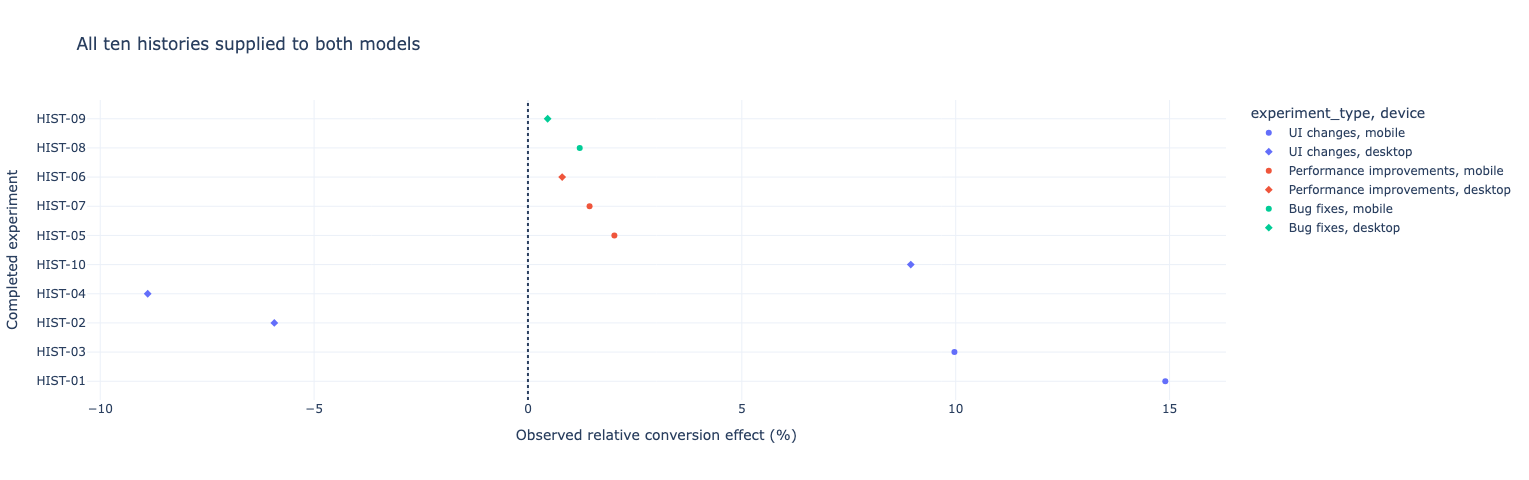

In [187]:
history = pd.DataFrame(ESTIMATION_HISTORY)
display(history.set_index('experiment_id').style.format(precision=4, thousands=',', na_rep='—'))
px.scatter(history, x='observed_uplift_pct', y='experiment_id', color='experiment_type',symbol='device',
           hover_data=['market','description'], height=480,
           labels={'observed_uplift_pct':'Observed relative conversion effect (%)','experiment_id':'Completed experiment'},
           title='All ten histories supplied to both models').add_vline(x=0,line_dash='dot').show()

In [ ]:
clairic_estimate = call_clairic(ESTIMATE_STATE, ESTIMATE_FIELDS)
luna_estimate = call_openai(ESTIMATE_STATE, ESTIMATE_FIELDS)

In [193]:
clairic_estimate

{'model': 'clairic',
 'answers': {'relative_uplift_pct': {'type': 'estimate',
   'value': 9.5,
   'mean': 9.48386514642002,
   'median': 10,
   'p10': 2.3,
   'p90': 15.9,
   'p_below': 1.972776954062283e-05,
   'p_above': 2.6621686629368924e-05}},
 'truncated': False,
 'usage': {'state_tokens': 893,
  'image_tokens': 0,
  'schema_tokens': 220,
  'input_tokens': 1113,
  'output_tokens': 0,
  'passes': 1},
 'latency_seconds': 0.2629398749995744}

In [192]:

BASE_EFFECT = {'UI changes':10., 'Performance improvements':1.5, 'Bug fixes':.8}
DEVICE_FACTOR = {'mobile':1.25, 'desktop':.75}
MARKET_FACTOR = {'Germany':1.2, 'UK':.8}
REFERENCE_UI_SIGN = 1  # Evaluator-only sign for this proposal; not included in the request.
expected_effect = BASE_EFFECT[PROPOSED_EXPERIMENT['experiment_type']] * DEVICE_FACTOR[PROPOSED_EXPERIMENT['device']] * MARKET_FACTOR[PROPOSED_EXPERIMENT['market']] * REFERENCE_UI_SIGN
print('Reference effect from the documented rule:', expected_effect, '% relative uplift')

estimate_rows = []
for model,result in [('clairic',clairic_estimate),('luna',luna_estimate)]:
    answer = result['answers']['relative_uplift_pct']
    estimate_rows.append({'model':model, **{k:answer[k] for k in ['median','p10','p90']}})
estimates = pd.DataFrame(estimate_rows)
estimates['absolute_error'] = (estimates['median']-expected_effect).abs()
estimate_comparison = estimates.set_index('model').rename(columns={'median':'value'})
estimate_comparison['elapsed_seconds'] = [clairic_estimate['latency_seconds'],luna_estimate['latency_seconds']]
estimate_comparison = pd.concat([
    pd.DataFrame([{'value':expected_effect,'absolute_error':0.0}],index=['expected']),
    estimate_comparison,
])
estimate_comparison.T.drop('elapsed_seconds', axis = 0).style.format(precision=4, thousands=',', na_rep='—')


Reference effect from the documented rule: 15.0 % relative uplift


,expected,clairic,luna
value,15.0000,10.0000,12.0000
absolute_error,0.0000,5.0000,3.0000
p10,—,2.3000,2.0000
p90,—,15.9000,20.0000


## 5. Forecasting 30 days — real daily rentals

Let's use actual Capital Bikeshare daily rentals, with a year of seasonal history and growth, instead of the simulated shop series. The forecast starts on **1 August 2012** and runs for 30 days. Future weather and future counts are not supplied.

Source: Fanaee-T, H. (2013), [Bike Sharing, UCI](https://doi.org/10.24432/C5W894), licensed [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Counts are unchanged; we use the source's calendar dates without timezone conversion. This is a familiar public dataset, so the example is illustrative rather than a decontaminated benchmark.

The literal state below is long because it contains the 365 dated observations. You can edit the prompt, history, horizon or fields directly.

Below the summer example are two alternatives: a spring-growth rental window and a monthly CO₂ trend/seasonality series. The latter predicts 12 months, clearly separated from the 30-day rental tasks.

In [201]:
FORECAST_STATE = """Real daily Capital Bikeshare rental counts. History ends 2012-07-31. Forecast 30 dates from 2012-08-01 through 2012-08-30. Use source calendar dates without timezone conversion. Only the dated history below is available; future weather is unknown.
date,weekday,rentals
2011-08-02,Tuesday,4845
2011-08-03,Wednesday,3574
2011-08-04,Thursday,4576
2011-08-05,Friday,4866
2011-08-06,Saturday,4294
2011-08-07,Sunday,3785
2011-08-08,Monday,4326
2011-08-09,Tuesday,4602
2011-08-10,Wednesday,4780
2011-08-11,Thursday,4792
2011-08-12,Friday,4905
2011-08-13,Saturday,4150
2011-08-14,Sunday,3820
2011-08-15,Monday,4338
2011-08-16,Tuesday,4725
2011-08-17,Wednesday,4694
2011-08-18,Thursday,3805
2011-08-19,Friday,4153
2011-08-20,Saturday,5191
2011-08-21,Sunday,3873
2011-08-22,Monday,4758
2011-08-23,Tuesday,5895
2011-08-24,Wednesday,5130
2011-08-25,Thursday,3542
2011-08-26,Friday,4661
2011-08-27,Saturday,1115
2011-08-28,Sunday,4334
2011-08-29,Monday,4634
2011-08-30,Tuesday,5204
2011-08-31,Wednesday,5058
2011-09-01,Thursday,5115
2011-09-02,Friday,4727
2011-09-03,Saturday,4484
2011-09-04,Sunday,4940
2011-09-05,Monday,3351
2011-09-06,Tuesday,2710
2011-09-07,Wednesday,1996
2011-09-08,Thursday,1842
2011-09-09,Friday,3544
2011-09-10,Saturday,5345
2011-09-11,Sunday,5046
2011-09-12,Monday,4713
2011-09-13,Tuesday,4763
2011-09-14,Wednesday,4785
2011-09-15,Thursday,3659
2011-09-16,Friday,4760
2011-09-17,Saturday,4511
2011-09-18,Sunday,4274
2011-09-19,Monday,4539
2011-09-20,Tuesday,3641
2011-09-21,Wednesday,4352
2011-09-22,Thursday,4795
2011-09-23,Friday,2395
2011-09-24,Saturday,5423
2011-09-25,Sunday,5010
2011-09-26,Monday,4630
2011-09-27,Tuesday,4120
2011-09-28,Wednesday,3907
2011-09-29,Thursday,4839
2011-09-30,Friday,5202
2011-10-01,Saturday,2429
2011-10-02,Sunday,2918
2011-10-03,Monday,3570
2011-10-04,Tuesday,4456
2011-10-05,Wednesday,4826
2011-10-06,Thursday,4765
2011-10-07,Friday,4985
2011-10-08,Saturday,5409
2011-10-09,Sunday,5511
2011-10-10,Monday,5117
2011-10-11,Tuesday,4563
2011-10-12,Wednesday,2416
2011-10-13,Thursday,2913
2011-10-14,Friday,3644
2011-10-15,Saturday,5217
2011-10-16,Sunday,5041
2011-10-17,Monday,4570
2011-10-18,Tuesday,4748
2011-10-19,Wednesday,2424
2011-10-20,Thursday,4195
2011-10-21,Friday,4304
2011-10-22,Saturday,4308
2011-10-23,Sunday,4381
2011-10-24,Monday,4187
2011-10-25,Tuesday,4687
2011-10-26,Wednesday,3894
2011-10-27,Thursday,2659
2011-10-28,Friday,3747
2011-10-29,Saturday,627
2011-10-30,Sunday,3331
2011-10-31,Monday,3669
2011-11-01,Tuesday,4068
2011-11-02,Wednesday,4186
2011-11-03,Thursday,3974
2011-11-04,Friday,4046
2011-11-05,Saturday,3926
2011-11-06,Sunday,3649
2011-11-07,Monday,4035
2011-11-08,Tuesday,4205
2011-11-09,Wednesday,4109
2011-11-10,Thursday,2933
2011-11-11,Friday,3368
2011-11-12,Saturday,4067
2011-11-13,Sunday,3717
2011-11-14,Monday,4486
2011-11-15,Tuesday,4195
2011-11-16,Wednesday,1817
2011-11-17,Thursday,3053
2011-11-18,Friday,3392
2011-11-19,Saturday,3663
2011-11-20,Sunday,3520
2011-11-21,Monday,2765
2011-11-22,Tuesday,1607
2011-11-23,Wednesday,2566
2011-11-24,Thursday,1495
2011-11-25,Friday,2792
2011-11-26,Saturday,3068
2011-11-27,Sunday,3071
2011-11-28,Monday,3867
2011-11-29,Tuesday,2914
2011-11-30,Wednesday,3613
2011-12-01,Thursday,3727
2011-12-02,Friday,3940
2011-12-03,Saturday,3614
2011-12-04,Sunday,3485
2011-12-05,Monday,3811
2011-12-06,Tuesday,2594
2011-12-07,Wednesday,705
2011-12-08,Thursday,3322
2011-12-09,Friday,3620
2011-12-10,Saturday,3190
2011-12-11,Sunday,2743
2011-12-12,Monday,3310
2011-12-13,Tuesday,3523
2011-12-14,Wednesday,3740
2011-12-15,Thursday,3709
2011-12-16,Friday,3577
2011-12-17,Saturday,2739
2011-12-18,Sunday,2431
2011-12-19,Monday,3403
2011-12-20,Tuesday,3750
2011-12-21,Wednesday,2660
2011-12-22,Thursday,3068
2011-12-23,Friday,2209
2011-12-24,Saturday,1011
2011-12-25,Sunday,754
2011-12-26,Monday,1317
2011-12-27,Tuesday,1162
2011-12-28,Wednesday,2302
2011-12-29,Thursday,2423
2011-12-30,Friday,2999
2011-12-31,Saturday,2485
2012-01-01,Sunday,2294
2012-01-02,Monday,1951
2012-01-03,Tuesday,2236
2012-01-04,Wednesday,2368
2012-01-05,Thursday,3272
2012-01-06,Friday,4098
2012-01-07,Saturday,4521
2012-01-08,Sunday,3425
2012-01-09,Monday,2376
2012-01-10,Tuesday,3598
2012-01-11,Wednesday,2177
2012-01-12,Thursday,4097
2012-01-13,Friday,3214
2012-01-14,Saturday,2493
2012-01-15,Sunday,2311
2012-01-16,Monday,2298
2012-01-17,Tuesday,2935
2012-01-18,Wednesday,3376
2012-01-19,Thursday,3292
2012-01-20,Friday,3163
2012-01-21,Saturday,1301
2012-01-22,Sunday,1977
2012-01-23,Monday,2432
2012-01-24,Tuesday,4339
2012-01-25,Wednesday,4270
2012-01-26,Thursday,4075
2012-01-27,Friday,3456
2012-01-28,Saturday,4023
2012-01-29,Sunday,3243
2012-01-30,Monday,3624
2012-01-31,Tuesday,4509
2012-02-01,Wednesday,4579
2012-02-02,Thursday,3761
2012-02-03,Friday,4151
2012-02-04,Saturday,2832
2012-02-05,Sunday,2947
2012-02-06,Monday,3784
2012-02-07,Tuesday,4375
2012-02-08,Wednesday,2802
2012-02-09,Thursday,3830
2012-02-10,Friday,3831
2012-02-11,Saturday,2169
2012-02-12,Sunday,1529
2012-02-13,Monday,3422
2012-02-14,Tuesday,3922
2012-02-15,Wednesday,4169
2012-02-16,Thursday,3005
2012-02-17,Friday,4154
2012-02-18,Saturday,4318
2012-02-19,Sunday,2689
2012-02-20,Monday,3129
2012-02-21,Tuesday,3777
2012-02-22,Wednesday,4773
2012-02-23,Thursday,5062
2012-02-24,Friday,3487
2012-02-25,Saturday,2732
2012-02-26,Sunday,3389
2012-02-27,Monday,4322
2012-02-28,Tuesday,4363
2012-02-29,Wednesday,1834
2012-03-01,Thursday,4990
2012-03-02,Friday,3194
2012-03-03,Saturday,4066
2012-03-04,Sunday,3423
2012-03-05,Monday,3333
2012-03-06,Tuesday,3956
2012-03-07,Wednesday,4916
2012-03-08,Thursday,5382
2012-03-09,Friday,4569
2012-03-10,Saturday,4118
2012-03-11,Sunday,4911
2012-03-12,Monday,5298
2012-03-13,Tuesday,5847
2012-03-14,Wednesday,6312
2012-03-15,Thursday,6192
2012-03-16,Friday,4378
2012-03-17,Saturday,7836
2012-03-18,Sunday,5892
2012-03-19,Monday,6153
2012-03-20,Tuesday,6093
2012-03-21,Wednesday,6230
2012-03-22,Thursday,6871
2012-03-23,Friday,8362
2012-03-24,Saturday,3372
2012-03-25,Sunday,4996
2012-03-26,Monday,5558
2012-03-27,Tuesday,5102
2012-03-28,Wednesday,5698
2012-03-29,Thursday,6133
2012-03-30,Friday,5459
2012-03-31,Saturday,6235
2012-04-01,Sunday,6041
2012-04-02,Monday,5936
2012-04-03,Tuesday,6772
2012-04-04,Wednesday,6436
2012-04-05,Thursday,6457
2012-04-06,Friday,6460
2012-04-07,Saturday,6857
2012-04-08,Sunday,5169
2012-04-09,Monday,5585
2012-04-10,Tuesday,5918
2012-04-11,Wednesday,4862
2012-04-12,Thursday,5409
2012-04-13,Friday,6398
2012-04-14,Saturday,7460
2012-04-15,Sunday,7132
2012-04-16,Monday,6370
2012-04-17,Tuesday,6691
2012-04-18,Wednesday,4367
2012-04-19,Thursday,6565
2012-04-20,Friday,7290
2012-04-21,Saturday,6624
2012-04-22,Sunday,1027
2012-04-23,Monday,3214
2012-04-24,Tuesday,5633
2012-04-25,Wednesday,6196
2012-04-26,Thursday,5026
2012-04-27,Friday,6233
2012-04-28,Saturday,4220
2012-04-29,Sunday,6304
2012-04-30,Monday,5572
2012-05-01,Tuesday,5740
2012-05-02,Wednesday,6169
2012-05-03,Thursday,6421
2012-05-04,Friday,6296
2012-05-05,Saturday,6883
2012-05-06,Sunday,6359
2012-05-07,Monday,6273
2012-05-08,Tuesday,5728
2012-05-09,Wednesday,4717
2012-05-10,Thursday,6572
2012-05-11,Friday,7030
2012-05-12,Saturday,7429
2012-05-13,Sunday,6118
2012-05-14,Monday,2843
2012-05-15,Tuesday,5115
2012-05-16,Wednesday,7424
2012-05-17,Thursday,7384
2012-05-18,Friday,7639
2012-05-19,Saturday,8294
2012-05-20,Sunday,7129
2012-05-21,Monday,4359
2012-05-22,Tuesday,6073
2012-05-23,Wednesday,5260
2012-05-24,Thursday,6770
2012-05-25,Friday,6734
2012-05-26,Saturday,6536
2012-05-27,Sunday,6591
2012-05-28,Monday,6043
2012-05-29,Tuesday,5743
2012-05-30,Wednesday,6855
2012-05-31,Thursday,7338
2012-06-01,Friday,4127
2012-06-02,Saturday,8120
2012-06-03,Sunday,7641
2012-06-04,Monday,6998
2012-06-05,Tuesday,7001
2012-06-06,Wednesday,7055
2012-06-07,Thursday,7494
2012-06-08,Friday,7736
2012-06-09,Saturday,7498
2012-06-10,Sunday,6598
2012-06-11,Monday,6664
2012-06-12,Tuesday,4972
2012-06-13,Wednesday,7421
2012-06-14,Thursday,7363
2012-06-15,Friday,7665
2012-06-16,Saturday,7702
2012-06-17,Sunday,6978
2012-06-18,Monday,5099
2012-06-19,Tuesday,6825
2012-06-20,Wednesday,6211
2012-06-21,Thursday,5905
2012-06-22,Friday,5823
2012-06-23,Saturday,7458
2012-06-24,Sunday,6891
2012-06-25,Monday,6779
2012-06-26,Tuesday,7442
2012-06-27,Wednesday,7335
2012-06-28,Thursday,6879
2012-06-29,Friday,5463
2012-06-30,Saturday,5687
2012-07-01,Sunday,5531
2012-07-02,Monday,6227
2012-07-03,Tuesday,6660
2012-07-04,Wednesday,7403
2012-07-05,Thursday,6241
2012-07-06,Friday,6207
2012-07-07,Saturday,4840
2012-07-08,Sunday,4672
2012-07-09,Monday,6569
2012-07-10,Tuesday,6290
2012-07-11,Wednesday,7264
2012-07-12,Thursday,7446
2012-07-13,Friday,7499
2012-07-14,Saturday,6969
2012-07-15,Sunday,6031
2012-07-16,Monday,6830
2012-07-17,Tuesday,6786
2012-07-18,Wednesday,5713
2012-07-19,Thursday,6591
2012-07-20,Friday,5870
2012-07-21,Saturday,4459
2012-07-22,Sunday,7410
2012-07-23,Monday,6966
2012-07-24,Tuesday,7592
2012-07-25,Wednesday,8173
2012-07-26,Thursday,6861
2012-07-27,Friday,6904
2012-07-28,Saturday,6685
2012-07-29,Sunday,6597
2012-07-30,Monday,7105
2012-07-31,Tuesday,7216
"""

FORECAST_FIELDS = {'daily_rentals': {'type': 'forecast',
                   'horizon': 30,
                   'interval': 'day',
                   'min': 0,
                   'max': 20000,
                   'step': 1,
                   'instructions': 'Forecast the next 30 daily bicycle rental counts, in chronological '
                                   'order from the explicit next date.'}}

FORECAST_START = '2012-08-01'
FORECAST_DATES = pd.date_range(FORECAST_START, periods=30, freq='D')
# print(FORECAST_STATE)
FORECAST_FIELDS

{'daily_rentals': {'type': 'forecast',
  'horizon': 30,
  'interval': 'day',
  'min': 0,
  'max': 20000,
  'step': 1,
  'instructions': 'Forecast the next 30 daily bicycle rental counts, in chronological order from the explicit next date.'}}

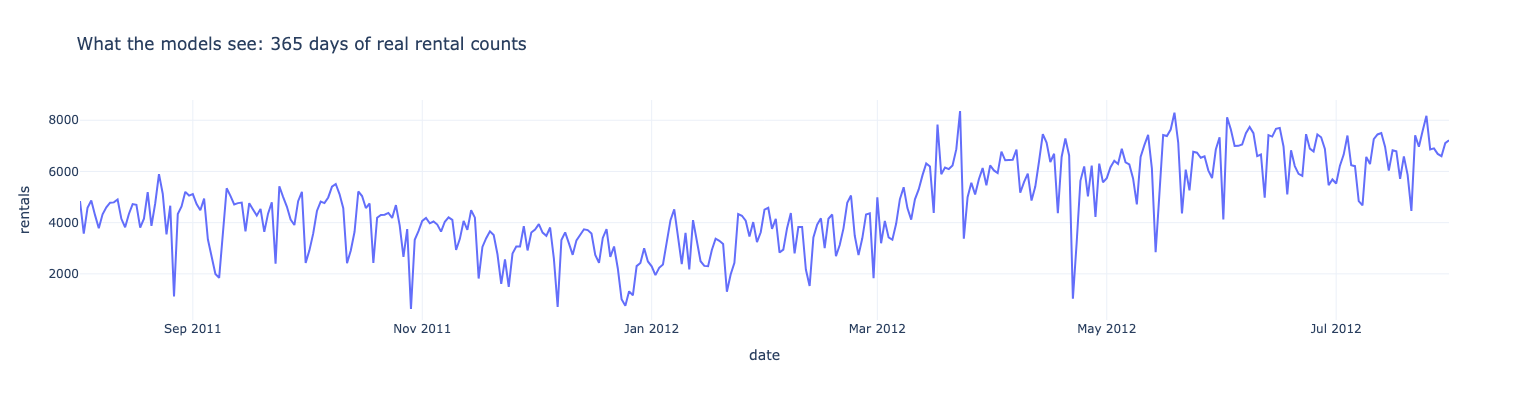

In [195]:
rentals = pd.read_csv('data/bike_sharing_daily.csv', parse_dates=['date'])
input_history = rentals[rentals.date < pd.Timestamp(FORECAST_START)].tail(365)
fig = px.line(input_history,x='date',y='rentals',title='What the models see: 365 days of real rental counts')
fig.update_layout(template='plotly_white',height=400)
fig.show()

In [196]:
clairic_forecast = call_clairic(FORECAST_STATE, FORECAST_FIELDS)
luna_forecast = call_openai(FORECAST_STATE, FORECAST_FIELDS)

clairic_steps = pd.DataFrame(clairic_forecast['answers']['daily_rentals']['steps'])
luna_steps = pd.DataFrame(luna_forecast['answers']['daily_rentals']['steps'])
assert len(clairic_steps) == len(luna_steps) == 30
forecast = pd.DataFrame({
    'expected':rentals.set_index('date').loc[FORECAST_DATES,'rentals'].values,
    'clairic':clairic_steps['median'].values,
    'luna':luna_steps['median'].values,
    'clairic_p10':clairic_steps.p10.values,'clairic_p90':clairic_steps.p90.values,
    'luna_p10':luna_steps.p10.values,'luna_p90':luna_steps.p90.values,
},index=FORECAST_DATES.strftime('%Y-%m-%d')).T
forecast.loc['clairic','elapsed_seconds'] = clairic_forecast['latency_seconds']
forecast.loc['luna','elapsed_seconds'] = luna_forecast['latency_seconds']
forecast.style.format(precision=4, thousands=',', na_rep='—').format(
    '{:,.0f}', na_rep='—', subset=pd.IndexSlice[:, forecast.columns.drop('elapsed_seconds')]
)


,2012-08-01,2012-08-02,2012-08-03,2012-08-04,2012-08-05,2012-08-06,2012-08-07,2012-08-08,2012-08-09,2012-08-10,2012-08-11,2012-08-12,2012-08-13,2012-08-14,2012-08-15,2012-08-16,2012-08-17,2012-08-18,2012-08-19,2012-08-20,2012-08-21,2012-08-22,2012-08-23,2012-08-24,2012-08-25,2012-08-26,2012-08-27,2012-08-28,2012-08-29,2012-08-30,elapsed_seconds
expected,"7,580","7,261","7,175","6,824","5,464","7,013","7,273","7,534","7,286","5,786","6,299","6,544","6,883","6,784","7,347","7,605","7,148","7,865","4,549","6,530","7,006","7,375","7,765","7,582","6,053","5,255","6,917","7,040","7,697","7,713",—
clairic,"6,645","6,523","6,455","6,126","5,990","6,230","6,420","6,383","6,414","6,211","5,989","5,976","6,308","6,362","6,449","6,427","6,300","6,069","6,131","6,447","6,452","6,572","6,525","6,359","6,233","6,257","6,606","6,570","6,534","6,597",0.6609
luna,"7,000","6,900","6,800","6,200","6,300","6,800","7,000","7,000","6,900","6,800","6,200","6,300","6,800","7,000","7,000","6,900","6,800","6,200","6,300","6,800","7,000","7,000","6,900","6,800","6,200","6,300","6,800","7,000","7,000","6,900",11.0698
clairic_p10,"4,890","4,699","4,628","4,225","4,149","4,417","4,633","4,512","4,462","4,254","4,078","4,075","4,418","4,456","4,489","4,440","4,299","4,102","4,155","4,517","4,481","4,517","4,400","4,228","4,165","4,173","4,661","4,498","4,458","4,491",—
clairic_p90,"8,343","8,274","8,193","7,974","7,843","7,879","8,028","8,134","8,257","8,108","7,969","7,942","8,044","8,124","8,333","8,345","8,268","8,100","8,119","8,306","8,352","8,543","8,552","8,437","8,364","8,364","8,509","8,551","8,525","8,581",—
luna_p10,"5,100","5,000","4,900","4,300","4,400","4,900","5,100","5,100","5,000","4,900","4,300","4,400","4,900","5,100","5,100","5,000","4,900","4,300","4,400","4,900","5,100","5,100","5,000","4,900","4,300","4,400","4,900","5,100","5,100","5,000",—
luna_p90,"8,700","8,600","8,500","8,100","8,200","8,500","8,700","8,700","8,600","8,500","8,100","8,200","8,500","8,700","8,700","8,600","8,500","8,100","8,200","8,500","8,700","8,700","8,600","8,500","8,100","8,200","8,500","8,700","8,700","8,600",—


Expected metric reference: zero MAE/MAPE/WAPE and 80% nominal interval coverage. Interval width and elapsed seconds have no fixed target. MAPE averages pointwise percentage errors over nonzero actuals; WAPE divides total absolute error by total absolute actuals.

In [212]:
forecast_metric_rows = [{'model':'expected','MAE':0.0,'MAPE_pct':0.0,'WAPE_pct':0.0,'coverage_80':.8}]
actual = rentals.set_index('date').loc[FORECAST_DATES,'rentals'].reset_index(drop=True).astype(float)
for model,steps,result in [('clairic',clairic_steps,clairic_forecast),('luna',luna_steps,luna_forecast)]:
    error = (steps['median']-actual).abs()
    forecast_metric_rows.append({'model':model,'MAE':error.mean(),
        'MAPE_pct':100*(error/actual.where(actual.ne(0))).mean(),
        'WAPE_pct':100*error.sum()/actual.abs().sum() if actual.abs().sum()>0 else None,
        'coverage_80':actual.between(steps.p10,steps.p90).mean(),
        'mean_interval_width':(steps.p90-steps.p10).mean(),'nonzero_actuals':int(actual.ne(0).sum()),
        'elapsed_seconds':result['latency_seconds']})
forecast_metrics = pd.DataFrame(forecast_metric_rows).set_index('model')
forecast_metrics.drop(['elapsed_seconds', 'coverage_80', 'nonzero_actuals'], axis = 1).drop('expected', axis = 0).style.format(precision=4, thousands=',', na_rep='—').format(
    '{:,.2f}', na_rep='—', 
)


,MAE,MAPE_pct,WAPE_pct,mean_interval_width
model,,,,
clairic,800.77,11.67,11.60,"3,846.37"
luna,527.03,8.07,7.63,"3,653.33"


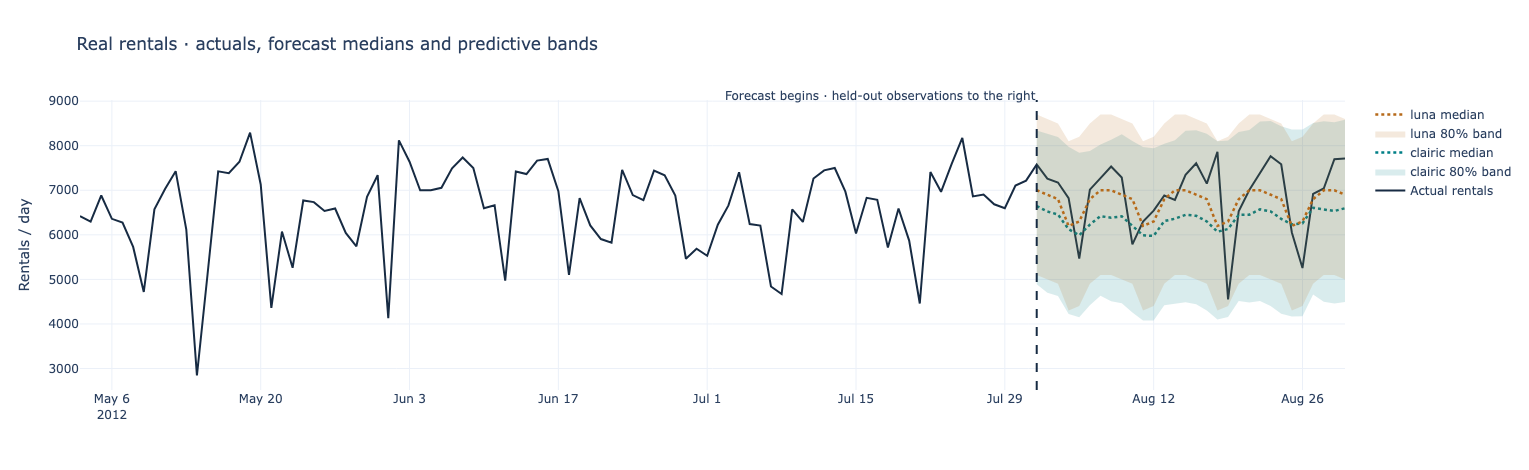

In [198]:
actual_plot = rentals[rentals.date.between(pd.Timestamp(FORECAST_START)-pd.Timedelta(days=90), FORECAST_DATES[-1])]
fig = go.Figure(go.Scatter(x=actual_plot.date,y=actual_plot.rentals,name='Actual rentals',
                           line=dict(color='#172b43',width=2)))
for model,steps in [('clairic',clairic_steps),('luna',luna_steps)]:
    fill = 'rgba(0,127,134,.15)' if model=='clairic' else 'rgba(182,106,26,.15)'
    fig.add_trace(go.Scatter(x=FORECAST_DATES,y=steps.p10,mode='lines',line_width=0,showlegend=False,hoverinfo='skip'))
    fig.add_trace(go.Scatter(x=FORECAST_DATES,y=steps.p90,mode='lines',line_width=0,fill='tonexty',fillcolor=fill,name=model+' 80% band'))
    fig.add_trace(go.Scatter(x=FORECAST_DATES,y=steps['median'],name=model+' median',line=dict(color=colors[model],dash='dot',width=2.5)))
fig.add_shape(type='line',x0=FORECAST_DATES[0],x1=FORECAST_DATES[0],y0=0,y1=1,yref='paper',line=dict(dash='dash',color='#172b43'))
fig.add_annotation(x=FORECAST_DATES[0],y=1.05,yref='paper',text='Forecast begins · held-out observations to the right',xanchor='right',showarrow=False)
fig.update_layout(template='plotly_white',title='Real rentals · actuals, forecast medians and predictive bands',yaxis_title='Rentals / day',height=470)
fig.show()

## 6. Overall quality on the extraction suite

This run covers readout extraction, count extraction, arithmetic, A/B chart reading and fact-only chart extraction: **120 cases, up to 240 requests** across both models. Effect estimation and forecasts are excluded. Only arithmetic is kept; direct and two-stage routes are excluded. The saved cases keep the language/detail variants; walkthrough edits do not change these frozen inputs.

Responses are saved locally after **each request** to `results/responses_v4.json`. Existing successful extraction responses are reused; saved results for excluded tasks stay in the cache. Set `RUN_FULL_SUITE=True` to run or resume. Scoring writes `results/request_status_v4.csv` and `results/quality_v4.csv`.

Failures count as incorrect; cases that haven't run yet are excluded from accuracy. Multiple views of an experiment are correlated, so these are descriptive results. Elapsed seconds are saved for both providers.


In [237]:
with open('data/model_cases.json') as f:
    cases = json.load(f)
EXTRACTION_TASKS = ['extraction', 'count_extraction', 'arithmetic', 'chart_ab', 'chart_facts']
cases = {case_id:case for case_id,case in cases.items() if case['task'] in EXTRACTION_TASKS
         and (case['task']!='arithmetic' or case['condition']=='one_shot')}
with open('data/expected_results.json') as f:
    expected_results = json.load(f)

suite_path = Path('results/responses_v4.json')
suite_path.parent.mkdir(exist_ok=True)
responses = json.loads(suite_path.read_text()) if suite_path.exists() else {}
pd.DataFrame(cases.values()).groupby(['task','language']).size().unstack(fill_value=0).style.format('{:,.0f}', na_rep='—')


language,de,en,es,fr
task,,,,
arithmetic,5,5,5,5
chart_ab,10,10,10,10
chart_facts,5,5,5,5
count_extraction,5,5,5,5
extraction,5,5,5,5


In [238]:
RUN_FULL_SUITE = True

if RUN_FULL_SUITE:
    for case_id,case in cases.items():
        saved = responses.get(case_id,{})
        if saved.get('fingerprint') != case['fingerprint']:
            saved = {'fingerprint':case['fingerprint']}
        for model in ['clairic','luna']:
            state_used = case['state']
            if 'from_counts' in case:
                upstream = responses.get(case['from_counts'],{}).get(model,{})
                if 'error_type' in upstream or not isinstance(upstream.get('answers'),dict):
                    saved[model] = {'error_type':'UpstreamUnavailable','latency_seconds':0.0,
                                    'pipeline_latency_seconds':upstream.get('latency_seconds',0.0)}
                    responses[case_id] = saved
                    suite_path.write_text(json.dumps(responses,ensure_ascii=False,indent=2))
                    continue
                extracted = {key:upstream['answers'].get(key,{}).get('value')
                             if isinstance(upstream['answers'].get(key),dict) else None
                             for key in cases[case['from_counts']]['fields']}
                state_used += '\n' + json.dumps(extracted,sort_keys=True)
            input_fingerprint = hashlib.sha256((case['fingerprint']+state_used).encode()).hexdigest()
            if model in saved and 'error_type' not in saved[model] and saved[model].get('input_fingerprint')==input_fingerprint:
                continue
            request_started = time.perf_counter()
            try:
                if model=='clairic':
                    result = call_clairic(state_used,case['fields'],images=case['images'])
                else:
                    result = call_openai(state_used,case['fields'],images=case['images'])
                result['input_fingerprint'] = input_fingerprint
                if 'from_counts' in case:
                    result['state_used'] = state_used
                    result['pipeline_latency_seconds'] = upstream.get('latency_seconds',0.0)+result['latency_seconds']
                saved[model] = result
            except Exception as error:
                saved[model] = {'error_type':type(error).__name__,'input_fingerprint':input_fingerprint,
                                'latency_seconds':time.perf_counter()-request_started}
            responses[case_id] = saved
            suite_path.write_text(json.dumps(responses,ensure_ascii=False,indent=2))
        print(case_id,{model:'error' if 'error_type' in saved[model] else 'saved' for model in ['clairic','luna']})
else:
    print('Ready to run the full suite; no calls made by this cell.')

EXP-001/read {'clairic': 'saved', 'luna': 'saved'}
EXP-001/math_one_shot {'clairic': 'saved', 'luna': 'saved'}
EXP-001/counts {'clairic': 'saved', 'luna': 'saved'}
EXP-002/read {'clairic': 'saved', 'luna': 'saved'}
EXP-002/math_one_shot {'clairic': 'saved', 'luna': 'saved'}
EXP-002/counts {'clairic': 'saved', 'luna': 'saved'}
EXP-003/read {'clairic': 'saved', 'luna': 'saved'}
EXP-003/math_one_shot {'clairic': 'saved', 'luna': 'saved'}
EXP-003/counts {'clairic': 'saved', 'luna': 'saved'}
EXP-004/read {'clairic': 'saved', 'luna': 'saved'}
EXP-004/math_one_shot {'clairic': 'saved', 'luna': 'saved'}
EXP-004/counts {'clairic': 'saved', 'luna': 'saved'}
EXP-005/read {'clairic': 'saved', 'luna': 'saved'}
EXP-005/math_one_shot {'clairic': 'saved', 'luna': 'saved'}
EXP-005/counts {'clairic': 'saved', 'luna': 'saved'}
EXP-006/read {'clairic': 'saved', 'luna': 'saved'}
EXP-006/math_one_shot {'clairic': 'saved', 'luna': 'saved'}
EXP-006/counts {'clairic': 'saved', 'luna': 'saved'}
EXP-007/read {'c

In [239]:
request_rows, quality_rows = [], []
for case_id, case in cases.items():
    target = expected_results[case_id]
    saved = responses.get(case_id, {})
    for model in ['clairic','luna']:
        result = saved.get(model) if saved.get('fingerprint') == case['fingerprint'] else None
        status = 'not_run' if result is None else 'error' if 'error_type' in result else 'ok'
        request_rows.append({'case':case_id,'model':model,'task':case['task'],'language':case['language'],
                             'condition':case['condition'],'status':status,
                             'latency_seconds':result.get('pipeline_latency_seconds',result.get('latency_seconds')) if result else None,
                             'request_seconds':result.get('latency_seconds') if result else None})
        if status == 'not_run':
            continue
        answers = result.get('answers', {}) if status=='ok' else {}
        if not isinstance(answers, dict):
            answers = {}
            if status=='ok': request_rows[-1]['status'] = 'invalid_output'
        base = {'case':case_id,'entity':case['entity'],'model':model,'task':case['task'],
                'language':case['language'],'condition':case['condition']}
        for field, expected in target['expected'].items():
            answer = answers.get(field, {})
            if not isinstance(answer, dict): answer = {}
            value = answer.get('value'); valid = 'value' in answer
            if value is not None:
                if case['fields'][field]['type']=='number':
                    valid = valid and isinstance(value,(int,float)) and not isinstance(value,bool) and math.isfinite(value)
                else:
                    valid = valid and isinstance(value,str)
            if expected is None:
                correct = valid and value is None
            elif isinstance(expected, (int,float)):
                valid = valid and isinstance(value, (int,float)) and not isinstance(value,bool) and math.isfinite(value)
                tolerance = target['metadata'].get('tolerances',{}).get(field,.01)
                if field.endswith(('_visitors','_orders')): tolerance = 0
                correct = valid and abs(value-expected) <= tolerance
            else:
                valid = valid and isinstance(value,str)
                normalized = ' '.join(unicodedata.normalize('NFC',value).strip().split()).casefold() if valid else ''
                correct = valid and normalized == ' '.join(unicodedata.normalize('NFC',expected).strip().split()).casefold()
            quality_rows.append({**base,'kind':'scalar','field':field,'expected':expected,'value':value,
                'valid':valid,'correct':bool(correct),'expected_missing':expected is None,'predicted_missing':value is None,
                'confidence':answer.get('confidence'),
                'abs_error':abs(value-expected) if valid and isinstance(expected,(int,float)) else None})
        for field, actual in target['estimates'].items():
            answer = answers.get(field,{})
            if not isinstance(answer, dict): answer = {}
            values = [answer.get(key) for key in ['p10','median','p90']]
            valid = all(isinstance(v,(int,float)) and not isinstance(v,bool) and math.isfinite(v) for v in values)
            valid = valid and case['fields'][field].get('min', -math.inf) <= values[0] <= values[1] <= values[2] <= case['fields'][field].get('max', math.inf)
            row = {**base,'kind':'estimate','field':field,'expected':actual,'valid':valid}
            if valid:
                lo,mid,hi = values
                row.update(value=mid,abs_error=abs(mid-actual),covered=lo<=actual<=hi,interval_width=hi-lo,
                           ape_pct=100*abs(mid-actual)/abs(actual) if actual!=0 else None)
            quality_rows.append(row)
        for field, future in target['forecasts'].items():
            answer = answers.get(field,{})
            steps = answer.get('steps',[]) if isinstance(answer,dict) else []
            length_ok = isinstance(steps,list) and len(steps)==len(future['actual'])
            for h, actual in enumerate(future['actual']):
                step = steps[h] if length_ok and isinstance(steps[h],dict) else {}
                values = [step.get(key) for key in ['p10','median','p90']]
                valid = all(isinstance(v,(int,float)) and not isinstance(v,bool) and math.isfinite(v) for v in values)
                valid = valid and case['fields'][field].get('min', -math.inf) <= values[0] <= values[1] <= values[2] <= case['fields'][field].get('max', math.inf)
                row = {**base,'kind':'forecast','field':field,'horizon':h+1,'expected':actual,'valid':valid}
                if valid:
                    lo,mid,hi = values
                    row.update(value=mid,abs_error=abs(mid-actual),covered=lo<=actual<=hi,interval_width=hi-lo,
                           ape_pct=100*abs(mid-actual)/abs(actual) if actual!=0 else None)
                quality_rows.append(row)

requests_df = pd.DataFrame(request_rows)
quality = pd.DataFrame(quality_rows)
requests_df.to_csv('results/request_status_v4.csv',index=False)
quality.to_csv('results/quality_v4.csv',index=False)
requests_df.groupby(['task','model','status']).size().unstack(fill_value=0).style.format('{:,.0f}', na_rep='—')


### Extraction, arithmetic and chart accuracy

Each case asks several questions. We score **each field answer** against the saved reference, then pool fields within these groups:

- **Experiment readouts:** find dates, audience, visitor/purchaser counts, revenue and the recommendation in analyst notes. Some facts require inference; some are unavailable.
- **Counts from prose:** extract the four A/B visitor and purchaser counts, including counts implied by totals.
- **Arithmetic:** return those four counts, both conversion rates, absolute uplift and relative uplift together in one call. Only the one-shot route is included.
- **A/B charts:** read counts, rates, intervals and the winning option from images. One version supplies dates in text; another requires reading them from a second chart alongside a distracting audience-mix chart. `equal` means inconclusive.

- **Chart facts only:** read 13 facts per case from the dashboard and timeline: experiment ID, dates, visitor/purchaser counts, conversion rates and interval endpoints. No winner or uplift question.

The notes vary in language and detail. Numeric answers use the saved per-field tolerance; text/date answers use normalized reference matching. A correctly returned missing value counts as correct. Failed requests and invalid answers count as incorrect; unrun cases are excluded. Thus **n means attempted field answers**, not independent experiments. All tables put the reference first. The charts label accuracy and sample size; the dotted line marks 100% accuracy.


For a concrete example of each group, here is one question from a saved case (each case asks several):

| Group | Example input | Question | Expected answer |
|---|---|---|---|
| Experiment readouts | “We ran the A/B test … from 2026-01-05 to 2026-01-25.” | When did EXP-001 end? | `2026-01-25` |
| Counts from prose | “Of the 118,223 eligible visitors, 59,117 got the new suggestions in B and the rest kept the current experience in A.” | How many visitors were assigned to A? | **59,106** (118,223 − 59,117) |
| Arithmetic | A has 1,585 purchasers / 59,106 visitors; B has 1,543 / 59,117. The prompt supplies counts, without calculated rates. | What is B’s purchase conversion rate? | **2.610%** (1,543 ÷ 59,117 × 100), returned alongside counts, A’s rate and uplift in the same call. |
| Chart facts only | EXP-003’s assignment timeline runs from 2026-01-29 to 2026-02-11; the prompt contains no dates. | What was the last assignment date? | **2026-02-11**, read from the timeline’s x-axis. |
| A/B charts | EXP-003’s [result dashboard](data/charts/EXP-003_comparison.png) shows A at 2.48% and B at 2.76%, with a positive B-minus-A difference interval. | Which option has better purchase conversion: A, B or equal? | **B**, because the difference interval is entirely above zero. A higher point estimate alone would not be enough. |

These examples illustrate the scoring questions; they are not extra API requests. The arithmetic question tests calculation rather than copying a supplied rate.


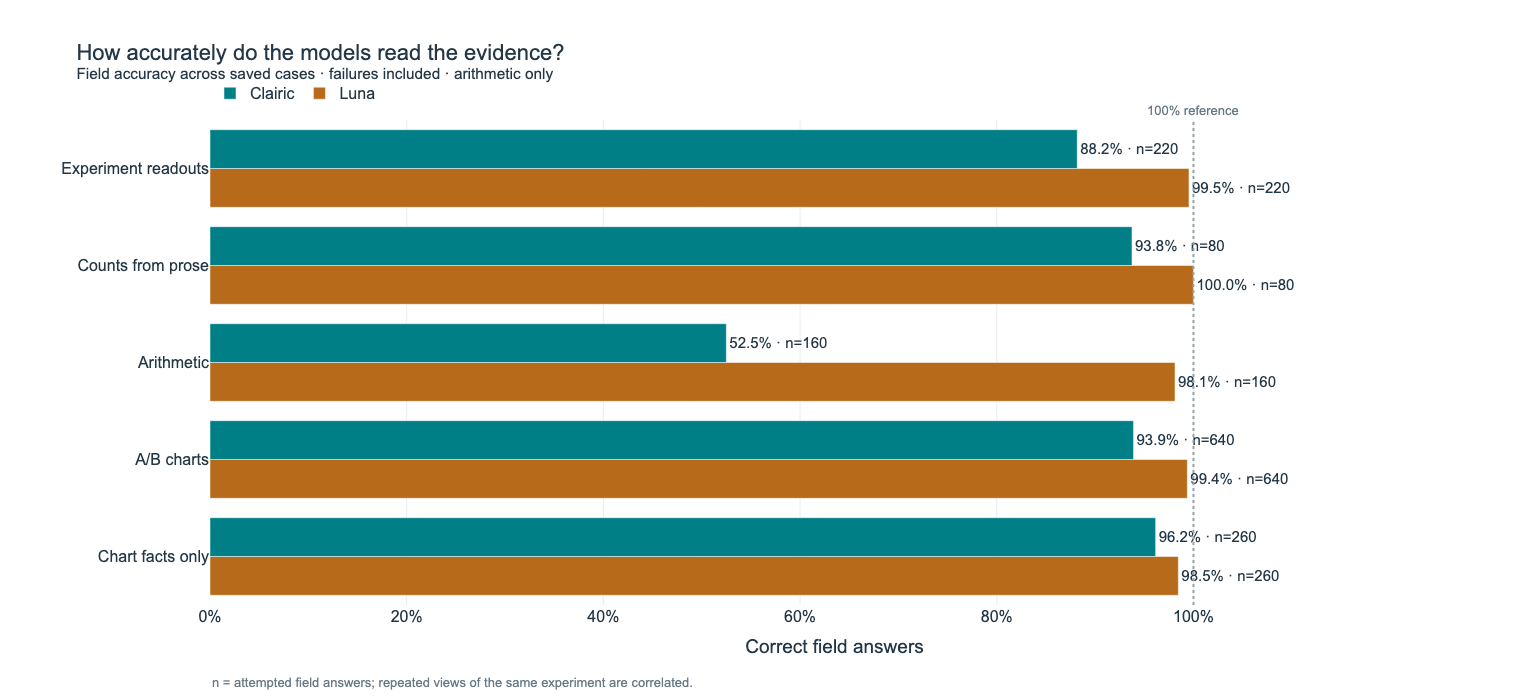

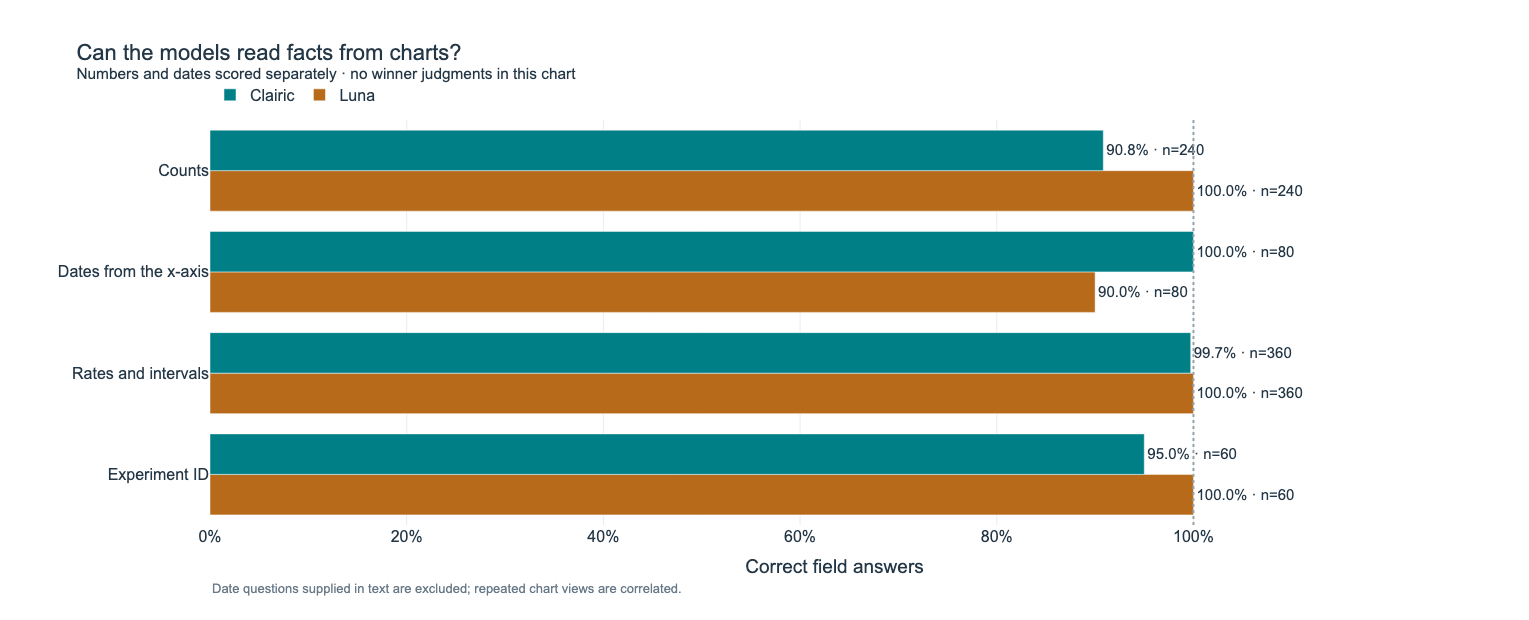

/var/folders/7v/1ln722x97kd8bchgxpmdkynw0000gn/T/ipykernel_7605/1717440160.py:84: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [244]:
article_charts = {}
task_labels = {'extraction':'Experiment readouts', 'count_extraction':'Counts from prose',
               'arithmetic':'Arithmetic', 'chart_ab':'A/B charts', 'chart_facts':'Chart facts only'}
article_layout = dict(template='plotly_white', font=dict(family='Arial',size=16,color='#243746'),
    paper_bgcolor='white', plot_bgcolor='white', margin=dict(l=210,r=70,t=120,b=95),
    legend=dict(title_text='',orientation='h',y=1.02,yanchor='bottom',x=0),
    hoverlabel=dict(font_size=14), width=1200)
if not quality.empty:
    scalar = quality[(quality.kind=='scalar') & quality.task.isin(EXTRACTION_TASKS) &
                     ((quality.task!='arithmetic') | (quality.condition=='one_shot'))]
    accuracy = scalar.groupby(['task','condition','model']).correct.mean().rename('accuracy').reset_index()
    accuracy_table = accuracy.pivot(index='model',columns=['task','condition'],values='accuracy')
    accuracy_table = pd.concat([pd.DataFrame(1.0,index=['expected'],columns=accuracy_table.columns),accuracy_table])
    display(accuracy_table.style.format(precision=4, thousands=',', na_rep='—'))

    overall_accuracy = scalar.groupby(['task','model']).agg(
        accuracy=('correct','mean'), fields=('correct','size'), correct_fields=('correct','sum')).reset_index()
    overall_accuracy['group'] = overall_accuracy.task.map(task_labels)
    overall_accuracy['provider'] = overall_accuracy.model.map({'clairic':'Clairic','luna':'Luna'})
    overall_accuracy['label'] = overall_accuracy.apply(
        lambda row:f"{row.accuracy:.1%} · n={int(row.fields):,}",axis=1)
    fig = px.bar(overall_accuracy,x='accuracy',y='group',color='provider',orientation='h',barmode='group',
        text='label',custom_data=['correct_fields','fields'],
        category_orders={'group':list(task_labels.values()),'provider':['Luna','Clairic']},
        color_discrete_map={'Clairic':colors['clairic'],'Luna':colors['luna']},
        labels={'accuracy':'Correct field answers','group':''})
    fig.update_layout(**article_layout,height=700,
        title=dict(text='How accurately do the models read the evidence?<br><sup>Field accuracy across saved cases · failures included · arithmetic only</sup>'))
    fig.update_layout(legend_traceorder='reversed')
    fig.update_traces(textposition='outside',cliponaxis=False,textfont_size=15,
        hovertemplate='%{y}<br>Accuracy: %{x:.1%}<br>Correct: %{customdata[0]:,} / %{customdata[1]:,}<extra>%{fullData.name}</extra>')
    fig.update_xaxes(range=[0,1.27],tickvals=[0,.2,.4,.6,.8,1],tickformat='.0%',gridcolor='#e8edf1',zeroline=False)
    fig.update_yaxes(showgrid=False,ticks='')
    fig.add_vline(x=1,line=dict(color='#96a3ad',dash='dot'))
    fig.add_annotation(x=1,y=1.04,xref='x',yref='paper',text='100% reference',showarrow=False,font=dict(size=13,color='#687987'))
    fig.add_annotation(x=0,y=-.18,xref='paper',yref='paper',xanchor='left',showarrow=False,
        text='n = attempted field answers; repeated views of the same experiment are correlated.',font=dict(size=13,color='#687987'))
    article_charts['extraction_accuracy'] = fig
    fig.show()

    # Dates count here only when they had to be read from an image.
    chart_facts_quality = scalar[scalar.task.isin(['chart_ab','chart_facts'])].copy()
    chart_facts_quality = chart_facts_quality[chart_facts_quality.field.isin(['experiment_id', 'start_date', 'end_date', 'control_visitors', 'control_orders', 'control_cvr_pct', 'control_ci_low_pct', 'control_ci_high_pct', 'treatment_visitors', 'treatment_orders', 'treatment_cvr_pct', 'treatment_ci_low_pct', 'treatment_ci_high_pct'])]
    chart_facts_quality = chart_facts_quality[~(chart_facts_quality.field.isin(['start_date','end_date']) &
                                               chart_facts_quality.condition.eq('text_dates'))]
    chart_facts_quality['fact_type'] = chart_facts_quality.field.map(
        lambda field:'Counts' if field.endswith(('_visitors','_orders')) else
        'Dates from the x-axis' if field in ['start_date','end_date'] else
        'Rates and intervals' if field.endswith('_pct') else 'Experiment ID')
    fact_accuracy = chart_facts_quality.groupby(['fact_type','model']).agg(
        accuracy=('correct','mean'),fields=('correct','size')).reset_index()
    if not fact_accuracy.empty:
        fact_accuracy['provider'] = fact_accuracy.model.map({'clairic':'Clairic','luna':'Luna'})
        fact_accuracy['label'] = fact_accuracy.apply(lambda row:f'{row.accuracy:.1%} · n={int(row.fields):,}',axis=1)
        fig = px.bar(fact_accuracy,x='accuracy',y='fact_type',color='provider',orientation='h',
            barmode='group',text='label',custom_data=['fields'],
            category_orders={'fact_type':['Counts','Dates from the x-axis','Rates and intervals','Experiment ID'],
                             'provider':['Luna','Clairic']},
            color_discrete_map={'Clairic':colors['clairic'],'Luna':colors['luna']},
            labels={'accuracy':'Correct field answers','fact_type':''})
        fig.update_layout(**article_layout,height=620,legend_traceorder='reversed',
            title=dict(text='Can the models read facts from charts?<br><sup>Numbers and dates scored separately · no winner judgments in this chart</sup>'))
        fig.update_traces(textposition='outside',cliponaxis=False,textfont_size=15,
            hovertemplate='%{y}<br>Accuracy %{x:.1%}<br>%{customdata[0]:,} field answers<extra>%{fullData.name}</extra>')
        fig.update_xaxes(range=[0,1.27],tickvals=[0,.2,.4,.6,.8,1],tickformat='.0%',gridcolor='#e8edf1',zeroline=False)
        fig.update_yaxes(showgrid=False)
        fig.add_vline(x=1,line=dict(color='#96a3ad',dash='dot'))
        fig.add_annotation(x=0,y=-.18,xref='paper',yref='paper',xanchor='left',showarrow=False,
            text='Date questions supplied in text are excluded; repeated chart views are correlated.',font=dict(size=13,color='#687987'))
        article_charts['chart_fact_accuracy'] = fig
        fact_accuracy.to_csv('results/chart_fact_accuracy.csv',index=False)
        fig.show()

    language_table = scalar.pivot_table(index='model',columns=['task','language'],values='correct',aggfunc='mean')
    display(pd.concat([pd.DataFrame(1.0,index=['expected'],columns=language_table.columns),language_table]).style.format(precision=4, thousands=',', na_rep='—'))
    winners = scalar[scalar.field=='better_option']
    if not winners.empty:
        winner_accuracy = winners.pivot_table(index='model',columns=['condition','expected'],values='correct',aggfunc='mean')
        display(pd.concat([pd.DataFrame(1.0,index=['expected'],columns=winner_accuracy.columns),winner_accuracy]).style.format(precision=4, thousands=',', na_rep='—'))
    timing = requests_df[(requests_df.status!='not_run') & requests_df.task.isin(EXTRACTION_TASKS) &
                        ((requests_df.task!='arithmetic') | (requests_df.condition=='one_shot'))].groupby(['task','condition','model']).latency_seconds.agg(
        median_seconds='median',p95_seconds=lambda x:x.quantile(.95)).reset_index()
    timing_table = timing.pivot(index='model',columns=['task','condition'],values=['median_seconds','p95_seconds'])
    display(pd.concat([pd.DataFrame(index=['expected'],columns=timing_table.columns),timing_table]).style.format(precision=4, thousands=',', na_rep='—'))
else:
    print('No scored responses yet. The request-status table shows what has not run.')


### How long do the calls take?

The first chart compares median response time per task, with p95 available on hover. The second compares the **same cases**: `Clairic seconds − Luna seconds`. Negative values mean Clairic was faster; positive values mean Luna was faster. We plot the median paired difference, which can differ from subtracting the two provider medians.

Only successful calls with a usable nonnegative timing enter these charts; the paired chart needs both models. These are observed end-to-end API times from this run, including network time, not a controlled throughput benchmark. Calls were sequential. Failed requests remain in accuracy scoring, and saved timings are reused without making new requests.


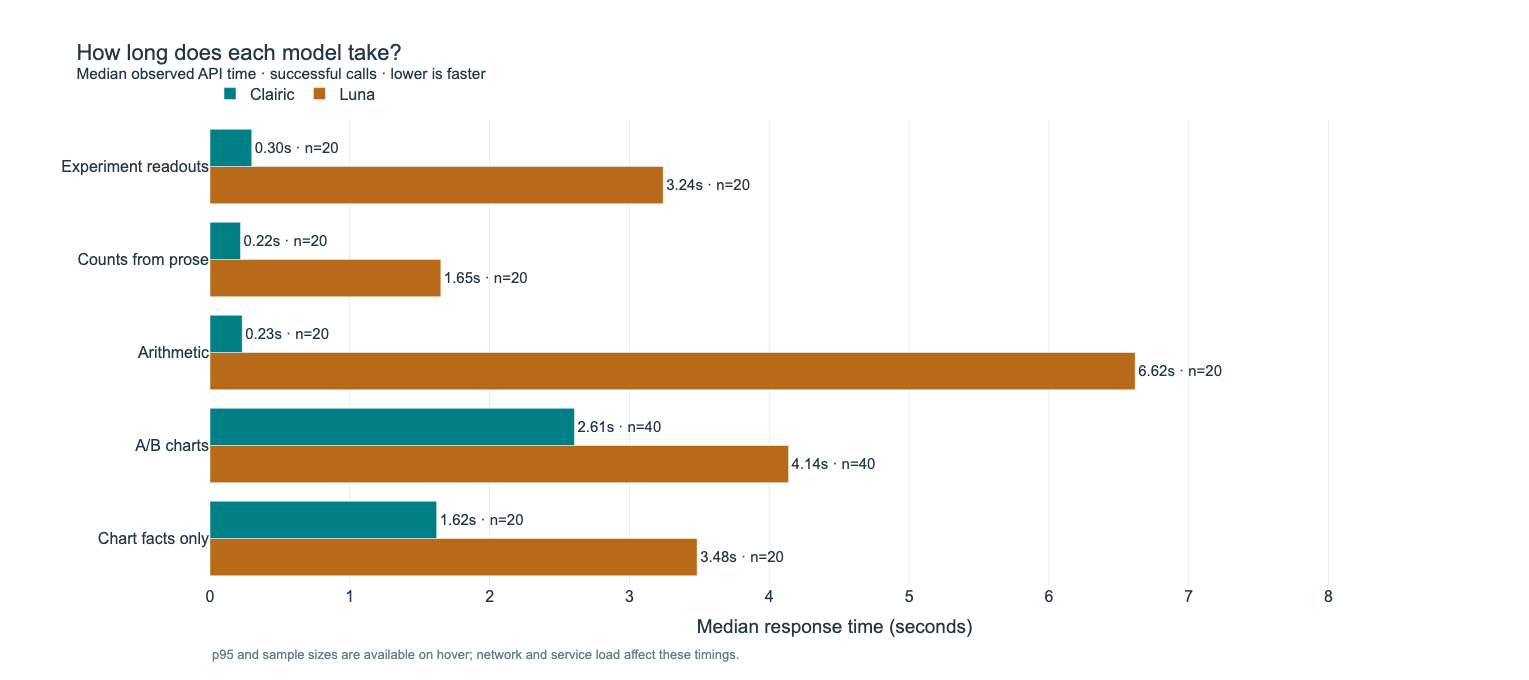

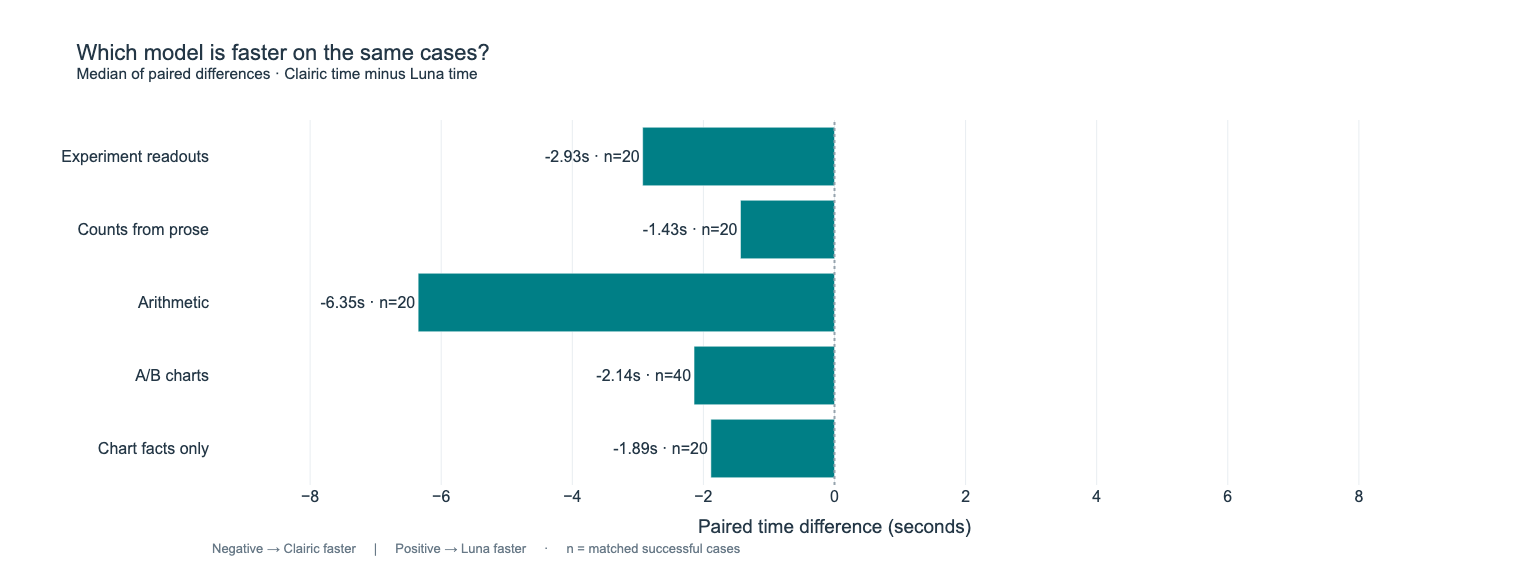

In [245]:
if not quality.empty:
    timed_requests = requests_df[(requests_df.status=='ok') & requests_df.task.isin(EXTRACTION_TASKS) &
        ((requests_df.task!='arithmetic') | (requests_df.condition=='one_shot'))].copy()
    timed_requests['elapsed_seconds'] = pd.to_numeric(timed_requests.request_seconds,errors='coerce')
    timed_requests = timed_requests[timed_requests.elapsed_seconds.ge(0) & timed_requests.elapsed_seconds.lt(float('inf'))]
    if not timed_requests.empty:
        provider_timing = timed_requests.groupby(['task','model']).agg(
            median_seconds=('elapsed_seconds','median'),p95_seconds=('elapsed_seconds',lambda x:x.quantile(.95)),
            calls=('elapsed_seconds','size')).reset_index()
        provider_timing['group'] = provider_timing.task.map(task_labels)
        provider_timing['provider'] = provider_timing.model.map({'clairic':'Clairic','luna':'Luna'})
        provider_timing['label'] = provider_timing.apply(lambda row:f'{row.median_seconds:.2f}s · n={int(row.calls):,}',axis=1)
        fig = px.bar(provider_timing,x='median_seconds',y='group',color='provider',orientation='h',
            barmode='group',text='label',custom_data=['p95_seconds','calls'],
            category_orders={'group':list(task_labels.values()),'provider':['Luna','Clairic']},
            color_discrete_map={'Clairic':colors['clairic'],'Luna':colors['luna']},
            labels={'median_seconds':'Median response time (seconds)','group':''})
        fig.update_layout(**article_layout,height=680,legend_traceorder='reversed',
            title=dict(text='How long does each model take?<br><sup>Median observed API time · successful calls · lower is faster</sup>'))
        fig.update_traces(textposition='outside',cliponaxis=False,textfont_size=15,
            hovertemplate='%{y}<br>Median %{x:.2f}s<br>p95 %{customdata[0]:.2f}s<br>%{customdata[1]:,} calls<extra>%{fullData.name}</extra>')
        fig.update_xaxes(range=[0,provider_timing.median_seconds.max()*1.35 or 1],gridcolor='#e8edf1',zeroline=False)
        fig.update_yaxes(showgrid=False)
        fig.add_annotation(x=0,y=-.17,xref='paper',yref='paper',xanchor='left',showarrow=False,
            text='p95 and sample sizes are available on hover; network and service load affect these timings.',font=dict(size=13,color='#687987'))
        article_charts['model_response_times'] = fig
        provider_timing.to_csv('results/model_response_times.csv',index=False)
        fig.show()

        paired_timing = timed_requests.pivot(index=['case','task'],columns='model',values='elapsed_seconds')
        if {'clairic','luna'} <= set(paired_timing.columns):
            paired_timing = paired_timing.dropna(subset=['clairic','luna']).copy()
            paired_timing['difference_seconds'] = paired_timing.clairic-paired_timing.luna
            differences = paired_timing.groupby('task').agg(
                median_difference_seconds=('difference_seconds','median'),pairs=('difference_seconds','size')).reset_index()
            if not differences.empty:
                differences['group'] = differences.task.map(task_labels)
                differences['label'] = differences.apply(
                    lambda row:f'{row.median_difference_seconds:+.2f}s · n={int(row.pairs):,}',axis=1)
                fig = go.Figure(go.Bar(x=differences.median_difference_seconds,y=differences['group'],orientation='h',
                    text=differences.label,textposition='outside',cliponaxis=False,
                    marker_color=['#007f86' if value<=0 else '#b66a1a' for value in differences.median_difference_seconds],
                    customdata=differences[['pairs']].values,
                    hovertemplate='%{y}<br>Median paired difference %{x:+.2f}s<br>%{customdata[0]:,} matched cases<extra></extra>'))
                fig.update_layout(**article_layout,height=580,showlegend=False,
                    title=dict(text='Which model is faster on the same cases?<br><sup>Median of paired differences · Clairic time minus Luna time</sup>'))
                extent = max(1,differences.median_difference_seconds.abs().max())
                fig.update_xaxes(range=[-extent*1.5,extent*1.5],title='Paired time difference (seconds)',gridcolor='#e8edf1',zeroline=False)
                fig.update_yaxes(categoryorder='array',categoryarray=list(task_labels.values())[::-1],showgrid=False)
                fig.add_vline(x=0,line=dict(color='#96a3ad',dash='dot'))
                fig.add_annotation(x=0,y=-.20,xref='paper',yref='paper',xanchor='left',showarrow=False,
                    text='Negative → Clairic faster     |     Positive → Luna faster     ·     n = matched successful cases',font=dict(size=13,color='#687987'))
                article_charts['model_response_time_difference'] = fig
                paired_timing.to_csv('results/paired_model_response_times.csv')
                fig.show()
else:
    print('Score saved responses first; no API requests are needed for timing charts.')


### Clairic confidence: how much can we trust it?

These charts pool **all included scalar answers**, including arithmetic. There is no task breakdown. The histogram shows where Clairic puts its confidence, split into correct and incorrect answers. Each bar covers a 0.1-wide bin; the last bin includes confidence 1. Missing/out-of-range confidence is counted separately, not placed at zero. The second histogram normalizes correct and incorrect answers separately: each group’s bins sum to 100%, letting us compare their confidence distributions despite different group sizes. It shows probability per bin, not percent correct within a bin.

Next, keep only answers with confidence **≥ X**. **Accuracy** is the fraction of retained answers scored correct. **Coverage** is the share of all attempted fields retained, including failed requests and missing confidence in the denominator. Invalid answers with high confidence still count as incorrect. Unrun cases are excluded. If no answers are retained, accuracy is undefined. We sweep X in steps of 0.01 and annotate 0, 0.5 and 0.9.

The final reliability chart compares average confidence with observed accuracy in ten bins. The diagonal is perfect agreement; points below it indicate overconfidence. These are field-level descriptive checks, with correlated questions and experiment variants. Hover for sample sizes. CSVs and article-ready charts save under `results/`; these cells make no API calls.


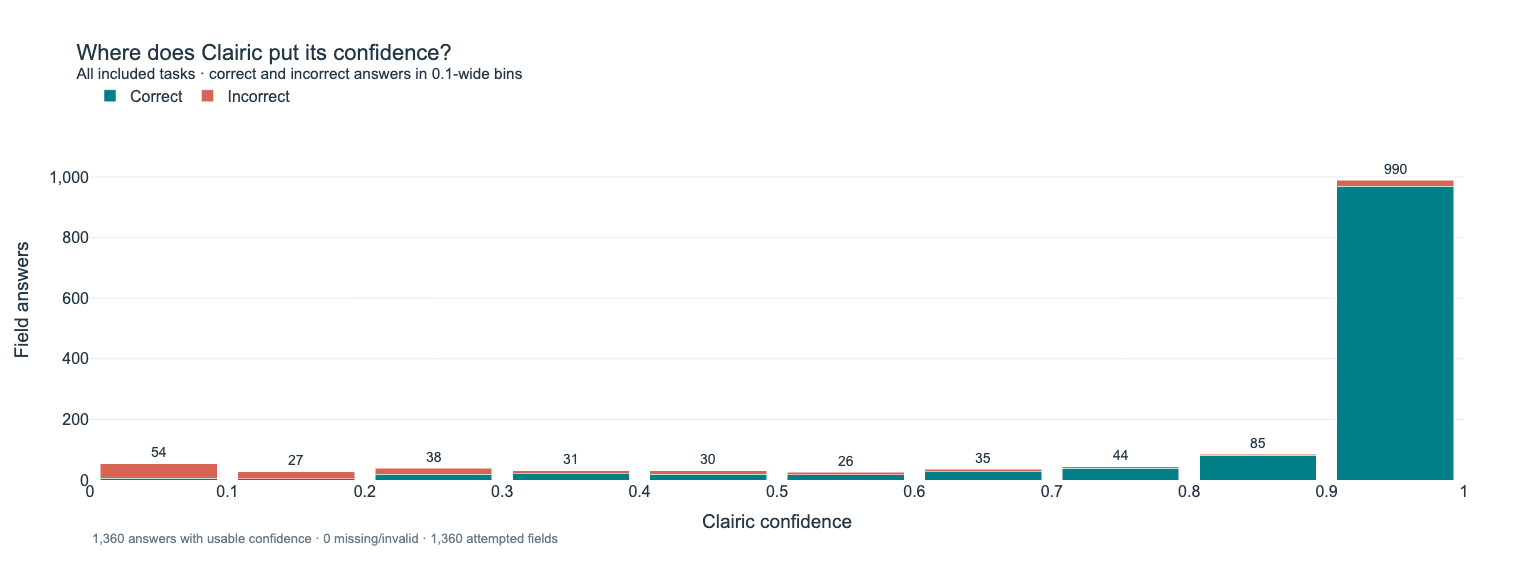

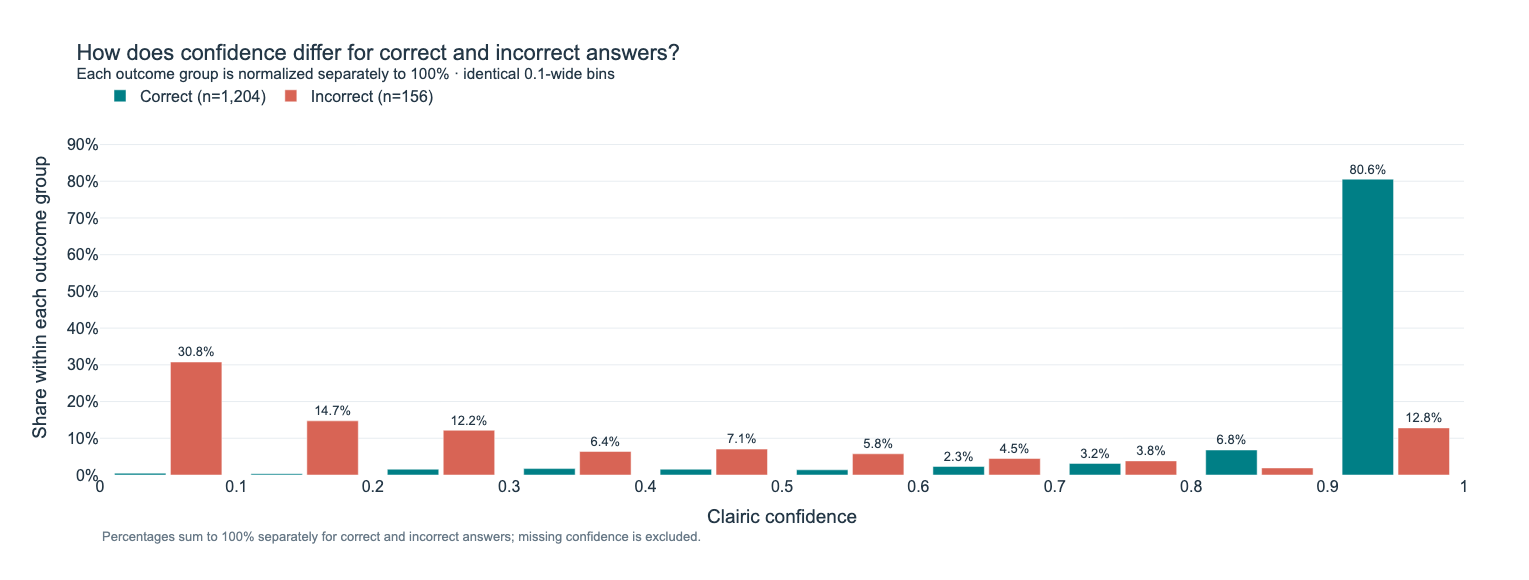

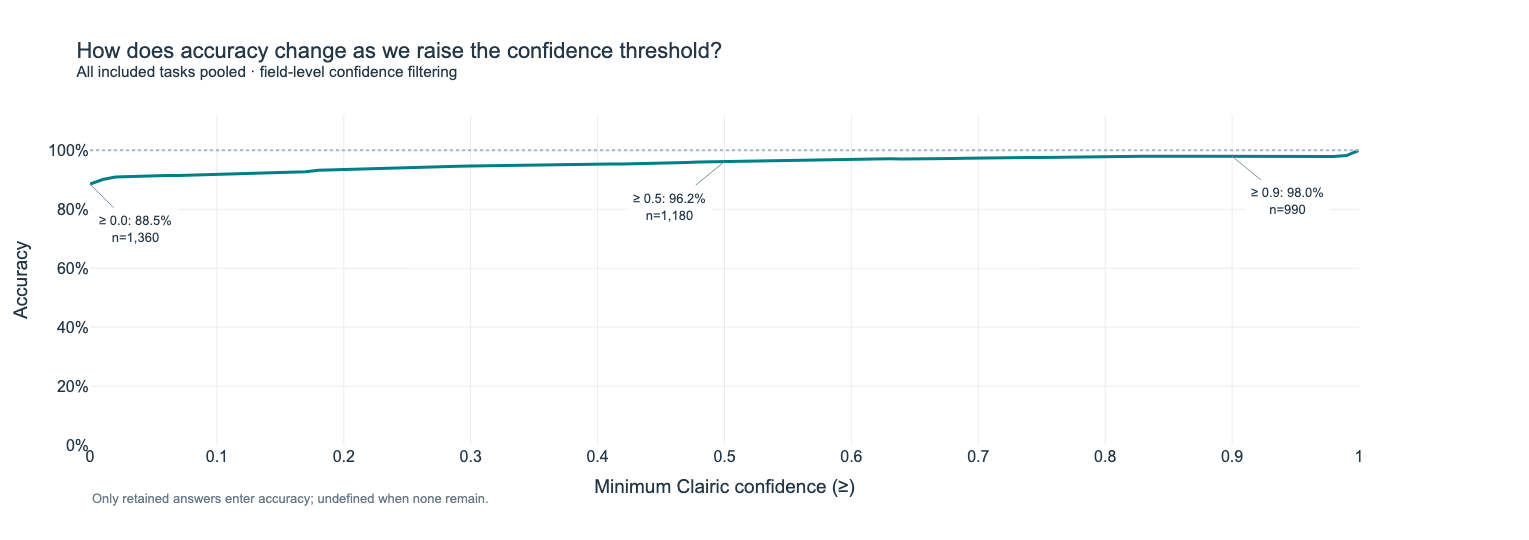

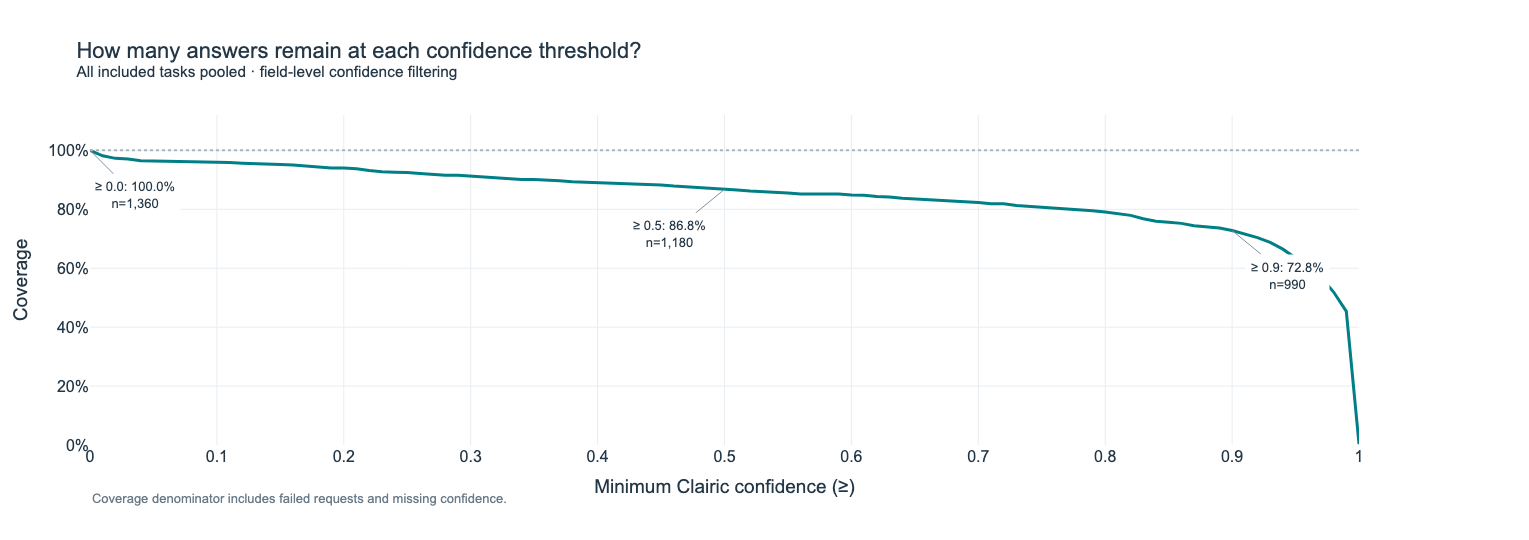

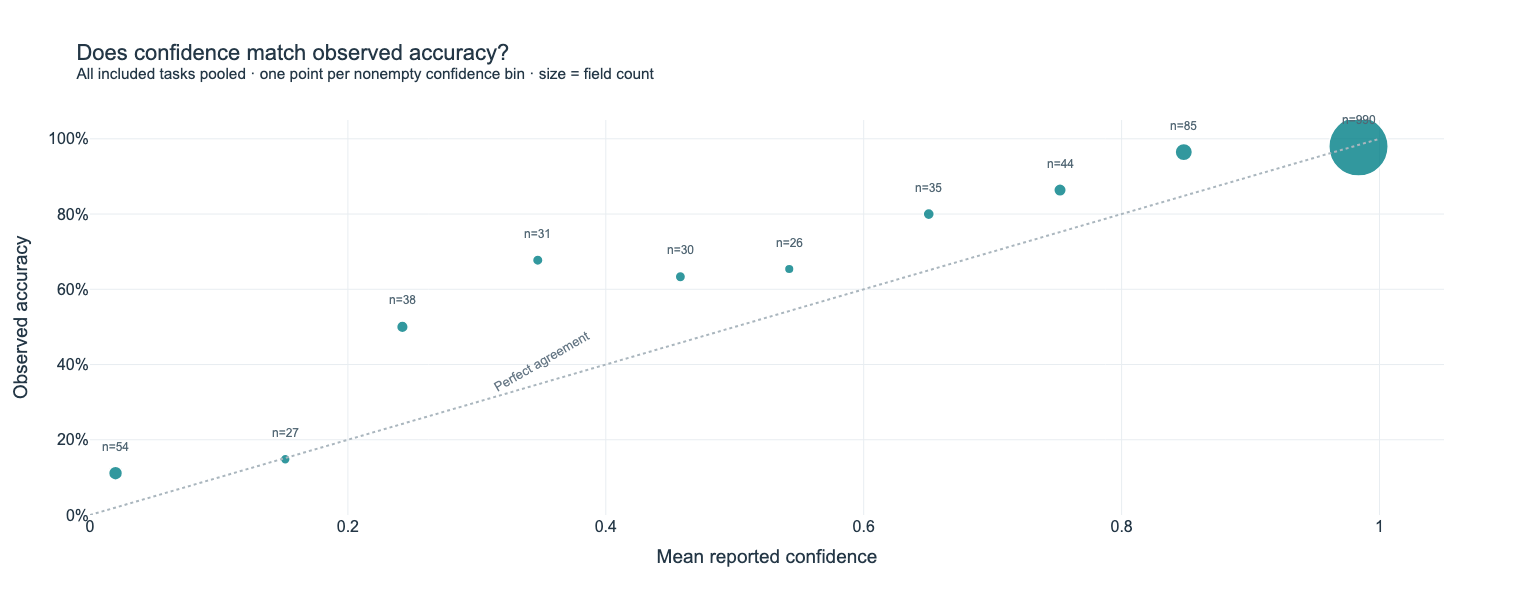

In [246]:
confidence_thresholds = pd.DataFrame()
confidence_bins = pd.DataFrame()
confidence_histogram = pd.DataFrame()
if not quality.empty:
    extraction = quality[(quality.model=='clairic') & (quality.kind=='scalar') &
                         quality.task.isin(EXTRACTION_TASKS) &
                         ((quality.task!='arithmetic') | (quality.condition=='one_shot'))].copy()
    extraction['confidence'] = pd.to_numeric(extraction['confidence'],errors='coerce')
    usable = extraction[extraction.confidence.between(0,1)].copy()
    attempted = len(extraction)
    missing_confidence = attempted-len(usable)
    threshold_rows, bin_rows, histogram_rows = [],[],[]
    if attempted:
        for threshold in [i/100 for i in range(101)]:
            retained = usable[usable.confidence >= threshold]
            threshold_rows.append({'threshold':threshold,
                'accuracy':retained.correct.mean() if len(retained) else None,
                'coverage':len(retained)/attempted,'retained_fields':len(retained),
                'attempted_fields':attempted,'correct_fields':int(retained.correct.sum()),
                'mean_confidence':retained.confidence.mean()})
        usable['bin_index'] = (usable.confidence*10).astype(int).clip(upper=9)
        for bin_index in range(10):
            bucket = usable[usable.bin_index==bin_index]
            if len(bucket):
                bin_rows.append({'bin_low':bin_index/10,'bin_high':(bin_index+1)/10,
                    'mean_confidence':bucket.confidence.mean(),'accuracy':bucket.correct.mean(),'fields':len(bucket)})
            for correct,label in [(True,'Correct'),(False,'Incorrect')]:
                histogram_rows.append({'bin_low':bin_index/10,'bin_high':(bin_index+1)/10,
                    'center':(bin_index+.5)/10,'outcome':label,'fields':int(bucket.correct.eq(correct).sum())})
    confidence_thresholds = pd.DataFrame(threshold_rows)
    confidence_bins = pd.DataFrame(bin_rows)
    confidence_histogram = pd.DataFrame(histogram_rows)
    if not confidence_histogram.empty:
        confidence_histogram['outcome_fields'] = confidence_histogram.groupby('outcome').fields.transform('sum')
        confidence_histogram['within_outcome_share'] = confidence_histogram.fields / confidence_histogram.outcome_fields.where(confidence_histogram.outcome_fields.gt(0))
        confidence_histogram['percent_label'] = confidence_histogram.within_outcome_share.map(
            lambda share:f'{share:.1%}' if pd.notna(share) and share>=.02 else '')
    confidence_thresholds.to_csv('results/clairic_confidence_thresholds.csv',index=False)
    confidence_bins.to_csv('results/clairic_confidence_bins.csv',index=False)
    confidence_histogram.to_csv('results/clairic_confidence_histogram.csv',index=False)

    if attempted:
        fig = px.bar(confidence_histogram,x='center',y='fields',color='outcome',barmode='stack',
            custom_data=['bin_low','bin_high'],category_orders={'outcome':['Correct','Incorrect']},
            color_discrete_map={'Correct':'#007f86','Incorrect':'#d86455'},
            labels={'center':'Clairic confidence','fields':'Field answers'})
        fig.update_layout(**article_layout,height=580,
            title=dict(text='Where does Clairic put its confidence?<br><sup>All included tasks · correct and incorrect answers in 0.1-wide bins</sup>'),
            bargap=.12)
        fig.update_layout(margin=dict(l=90,r=65,t=120,b=100))
        fig.update_traces(width=.085,hovertemplate='Confidence %{customdata[0]:.1f}–%{customdata[1]:.1f}<br>%{y:,} fields<extra>%{fullData.name}</extra>')
        for center,total in confidence_histogram.groupby('center').fields.sum().items():
            if total:
                fig.add_annotation(x=center,y=total,text=f'{int(total):,}',showarrow=False,yshift=12,font_size=14)
        fig.update_xaxes(range=[0,1],dtick=.1,showgrid=False,zeroline=False)
        fig.update_yaxes(rangemode='tozero',gridcolor='#e8edf1',tickformat=',d',zeroline=False)
        largest = confidence_histogram.groupby('center').fields.sum().max()
        fig.update_yaxes(range=[0,max(1,largest)*1.2])
        fig.add_annotation(x=0,y=-.19,xref='paper',yref='paper',xanchor='left',showarrow=False,
            text=f'{len(usable):,} answers with usable confidence · {missing_confidence:,} missing/invalid · {attempted:,} attempted fields',
            font=dict(size=13,color='#687987'))
        article_charts['clairic_confidence_histogram'] = fig
        fig.show()

    if attempted:
        fig = px.bar(confidence_histogram,x='center',y='within_outcome_share',color='outcome',
            barmode='group',text='percent_label',custom_data=['bin_low','bin_high','fields','outcome_fields'],
            category_orders={'outcome':['Correct','Incorrect']},
            color_discrete_map={'Correct':'#007f86','Incorrect':'#d86455'},
            labels={'center':'Clairic confidence','within_outcome_share':'Share within each outcome group'})
        fig.update_layout(**article_layout,height=580,
            title=dict(text='How does confidence differ for correct and incorrect answers?<br><sup>Each outcome group is normalized separately to 100% · identical 0.1-wide bins</sup>'),
            bargap=.18,bargroupgap=.08)
        fig.update_layout(margin=dict(l=100,r=65,t=120,b=105))
        fig.update_traces(textposition='outside',cliponaxis=False,textfont_size=13,
            hovertemplate='Confidence %{customdata[0]:.1f}–%{customdata[1]:.1f}<br>%{y:.1%} of this outcome group<br>%{customdata[2]:,} / %{customdata[3]:,} fields<extra>%{fullData.name}</extra>')
        outcome_totals = confidence_histogram.groupby('outcome').fields.sum()
        for trace in fig.data:
            trace.name += f' (n={int(outcome_totals[trace.name]):,})'
        fig.update_xaxes(range=[0,1],dtick=.1,showgrid=False,zeroline=False)
        top = confidence_histogram.within_outcome_share.max()
        fig.update_yaxes(range=[0,min(1.05,max(.1,top)*1.2)] if pd.notna(top) else [0,1],
                         tickformat='.0%',gridcolor='#e8edf1',zeroline=False)
        fig.add_annotation(x=0,y=-.20,xref='paper',yref='paper',xanchor='left',showarrow=False,
            text='Percentages sum to 100% separately for correct and incorrect answers; missing confidence is excluded.',
            font=dict(size=13,color='#687987'))
        article_charts['clairic_confidence_histogram_normalized'] = fig
        fig.show()

    if not confidence_thresholds.empty:
        for metric,title in [('accuracy','How does accuracy change as we raise the confidence threshold?'),
                             ('coverage','How many answers remain at each confidence threshold?')]:
            fig = px.line(confidence_thresholds,x='threshold',y=metric,
                custom_data=['retained_fields','attempted_fields','correct_fields'],
                labels={'threshold':'Minimum Clairic confidence (≥)',metric:metric.title()})
            fig.update_layout(**article_layout,height=540,
                title=dict(text=title+'<br><sup>All included tasks pooled · field-level confidence filtering</sup>'))
            fig.update_layout(margin=dict(l=90,r=170,t=115,b=95),showlegend=False)
            fig.update_traces(line=dict(color='#007f86',width=3),connectgaps=False,
                hovertemplate='Threshold ≥ %{x:.2f}<br>'+metric.title()+': %{y:.1%}<br>Retained %{customdata[0]:,} / %{customdata[1]:,} fields<extra></extra>')
            fig.update_xaxes(range=[0,1],dtick=.1,gridcolor='#e8edf1',zeroline=False)
            fig.update_yaxes(range=[0,1.12],tickvals=[0,.2,.4,.6,.8,1],tickformat='.0%',gridcolor='#e8edf1',zeroline=False)
            fig.add_hline(y=1,line=dict(color='#aab6be',dash='dot'))
            for threshold,offset in [(0,45),(.5,-55),(.9,55)]:
                row = confidence_thresholds.loc[confidence_thresholds.threshold.eq(threshold)].iloc[0]
                value = row[metric]
                if pd.notna(value):
                    fig.add_annotation(x=threshold,y=value,ax=offset,ay=45,arrowhead=0,arrowcolor='#80929e',
                        text=f'≥ {threshold:.1f}: {value:.1%}<br>n={int(row.retained_fields):,}',
                        bgcolor='white',borderpad=5,font=dict(size=13,color='#243746'))
            fig.add_annotation(x=0,y=-.19,xref='paper',yref='paper',xanchor='left',showarrow=False,
                text='Coverage denominator includes failed requests and missing confidence.' if metric=='coverage' else 'Only retained answers enter accuracy; undefined when none remain.',
                font=dict(size=13,color='#687987'))
            article_charts['clairic_confidence_'+metric] = fig
            fig.write_html('results/clairic_confidence_'+metric+'.html',include_plotlyjs=True)
            fig.show()
    if not confidence_bins.empty:
        fig = px.scatter(confidence_bins,x='mean_confidence',y='accuracy',size='fields',
            custom_data=['bin_low','bin_high','fields'],size_max=42,
            labels={'mean_confidence':'Mean reported confidence','accuracy':'Observed accuracy'})
        fig.update_layout(**article_layout,height=610,
            title=dict(text='Does confidence match observed accuracy?<br><sup>All included tasks pooled · one point per nonempty confidence bin · size = field count</sup>'))
        fig.update_layout(margin=dict(l=90,r=85,t=120,b=95),showlegend=False)
        fig.update_traces(marker=dict(color='#007f86',opacity=.8,line=dict(color='white',width=1.5)),
            hovertemplate='Confidence %{x:.3f}<br>Accuracy %{y:.1%}<br>Bin %{customdata[0]:.1f}–%{customdata[1]:.1f}<br>%{customdata[2]:,} fields<extra></extra>')
        fig.add_shape(type='line',x0=0,y0=0,x1=1,y1=1,line=dict(color='#aab6be',dash='dot'))
        fig.add_annotation(x=.35,y=.35,text='Perfect agreement',showarrow=False,textangle=-30,yshift=22,font=dict(size=13,color='#687987'))
        fig.update_xaxes(range=[0,1.05],dtick=.2,gridcolor='#e8edf1',zeroline=False)
        fig.update_yaxes(range=[0,1.05],tickformat='.0%',dtick=.2,gridcolor='#e8edf1',zeroline=False)
        for row in confidence_bins.itertuples():
            fig.add_annotation(x=row.mean_confidence,y=row.accuracy,text=f'n={row.fields:,}',
                showarrow=False,yshift=27,font=dict(size=12,color='#526774'))
        article_charts['clairic_confidence_reliability'] = fig
        fig.write_html('results/clairic_confidence_reliability.html',include_plotlyjs=True)
        fig.show()
else:
    print('Run the scoring cell above after loading the saved responses.')


In [247]:
# Interactive files for exploring; PNG/SVG copies for the article.
chart_directory = Path('results/article_charts')
chart_directory.mkdir(parents=True,exist_ok=True)
for name,fig in article_charts.items():
    fig.write_html(str(chart_directory/(name+'.html')),include_plotlyjs=True)
    try:
        fig.write_image(str(chart_directory/(name+'.png')),scale=2)
        fig.write_image(str(chart_directory/(name+'.svg')))
    except (ImportError,ValueError,RuntimeError) as error:
        print(name, 'HTML saved; static export needs Plotly image-export support:', str(error).splitlines()[0])
print('Charts saved to',chart_directory.resolve())


Charts saved to /Users/marie/Documents/github/miptgirl_medium/clairic_product_analytics/results/article_charts


The extraction response cache, scoring CSVs, confidence summaries and interactive charts are saved locally under `results/`. Re-run the scoring and confidence cells to explore saved responses without making model calls.
